# Big Mart Sales Prediction


## Project Overview


In [ ]:
# ============================================================
# PROJECT: Big Mart Sales Prediction
# ============================================================
#
# Dataset: BigMart Sales Data
# Data Source: Kaggle
# Data URL: https://www.kaggle.com/datasets/brijbhushannanda1979/bigmart-sales-data
# Dataset File: big_mart_sales.csv
# Task: Regression
# Target Variable: Item_Outlet_Sales
#
# Objective:
# Predict product sales across Big Mart stores using
# regression algorithms while implementing an end-to-end
# machine learning workflow from raw data to model prediction.
#
# Description:
# End-to-end regression project covering data auditing,
# cleaning, exploratory data analysis, feature engineering,
# transformation, categorical encoding, preprocessing,
# feature selection, model training, hyperparameter tuning,
# cross-validation, residual analysis, visualization, error
# handling, model persistence, and prediction.
#
# Repository Description:
# Machine learning project for predicting product sales across
# Big Mart stores using regression models, Python,
# scikit-learn, and the BigMart Sales Data dataset.
#
# Model: Regression Models
# Framework: Scikit-learn
# Dependencies: Python, Pandas, NumPy, Matplotlib, Seaborn,
#               Scikit-learn, Statsmodels, SciPy
#
# Evaluation Metrics: MAE, MSE, RMSE, R²
#
# Project Stage: Development
#
# Python Version: 3.12
#
# Version: 1.0.0
# Version Label: Initial Development
#
# Date Started: 2026-10-25
# Last Updated: 2026-10-25
#
# Author: Samuel Ablordeppey
# ============================================================

## Imports


In [457]:
# Standard library
from pathlib import Path
import sys
from IPython.display import display

# Data manipulation
import numpy as np
import pandas as pd
import data_profiling

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Machine learning
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, cross_val_score, KFold, cross_validate, GridSearchCV
from sklearn.feature_selection import RFECV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

## Environment & Reproducibility


In [2]:
# Python Version
print(f"Python: {sys.version}")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# visualization settings.
plt.rcParams["figure.figsize"] = (10, 6)
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


## Configurations


### Project Paths


In [3]:
# Project Paths
BASE_DIR = Path.cwd().parent

NOTEBOOKS_DIR = BASE_DIR / "notebooks"

DATA_DIR = BASE_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

OUTPUT_DIR = BASE_DIR / "outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"

MODEL_DIR = BASE_DIR / "models"

### File Paths


In [4]:
RAW_DATA_FILE = RAW_DATA_DIR / "big_mart_sales.csv"

### Machine Learning Config


In [770]:
# ============================================================
# COLUMN CONFIGURATION
# ============================================================
TARGET_COLUMN = {
    "key": "Item_Outlet_Sales",
    "feature": "Item Outlet Sales",
    "label": "Big Mart Product Sales",
}


FEATURES_TO_CREATE = [
    "item_visibility_ratio",
]

EXCLUDE_COLUMNS = {
    "eda": [],
    "modeling": [
        "Item_Weight",
        "Item_Identifier",
        "Item_Type",
        "Outlet_Identifier",
    ],
}
EXCLUDE_COLUMNS = {
    **EXCLUDE_COLUMNS,
    "multicollinearity": [
        "Item_Visibility",
        *EXCLUDE_COLUMNS['modeling']
    ],
}


# ============================================================
# MACHINE LEARNING CONFIGURATION
# ============================================================
TEST_SIZE = 0.20
RANDOM_STATE = 42


# ============================================================
# EVALUATION CONFIGURATION
# ============================================================
CROSS_VALIDATION_FOLDS = 5


# ============================================================
# PREPROCESSING CONFIGURATION
# ============================================================
NUMERICAL_IMPUTATION = "median"
CATEGORICAL_IMPUTATION = "most_frequent"


# ============================================================
# FEATURE SELECTION CONFIGURATION
# ============================================================
CORRELATION_THRESHOLD = 0.80
VIF_THRESHOLD = 5

### Model Configuration


In [7]:
REGRESSION_MODEL_CONFIG = {
    "Linear Regression": {
        "estimator": LinearRegression(),
        "baseline": True,
        "param_grid": {
            "model__fit_intercept": [True, False]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Ridge": {
        "estimator": Ridge(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [0.1, 1.0, 10.0, 100.0]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Lasso": {
        "estimator": Lasso(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [1.0, 10.0, 100.0],
            "model__max_iter": [20000]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Elastic Net": {
        "estimator": ElasticNet(),
        "baseline": False,
        "param_grid": {
            "model__alpha": [0.1, 1.0, 10.0],
            "model__l1_ratio": [0.2, 0.5, 0.8],
            "model__max_iter": [20000]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Random Forest": {
        "estimator": RandomForestRegressor(
            random_state=RANDOM_STATE
        ),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 2]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "Gradient Boosting": {
        "estimator": GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [2, 3, 4]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "KNN": {
        "estimator": KNeighborsRegressor(),
        "baseline": False,
        "param_grid": {
            "model__n_neighbors": [3, 5, 7, 11],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "SVR": {
        "estimator": SVR(),
        "baseline": False,
        "param_grid": {
            "model__C": [1, 10, 100],
            "model__epsilon": [0.1, 0.2],
            "model__kernel": ["linear", "rbf"]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "XGBoost": {
        "estimator": XGBRegressor(
            random_state=RANDOM_STATE,
            objective="reg:squarederror",
            n_jobs=-1
        ),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [2, 3, 5],
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    },

    "LightGBM": {
        "estimator": LGBMRegressor(
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        ),
        "baseline": False,
        "param_grid": {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.1],
            "model__max_depth": [-1, 3, 5],
            "model__num_leaves": [15, 31],
            "model__subsample": [0.8, 1.0],
            "model__colsample_bytree": [0.8, 1.0]
        },
        "model_diagnostics": [
            "residuals_vs_predicted",
            "residual_distribution",
            "normal_qq_plot",
            "residuals_vs_actual",
            "actual_vs_predicted"
        ]
    }
}



# ============================================================
# DERIVE EXISTING VARIABLES AUTOMATICALLY
# ============================================================

BASELINE_MODEL_NAME = next(
    name
    for name, config in REGRESSION_MODEL_CONFIG.items()
    if config["baseline"]
)

BASELINE_MODEL = clone(
    REGRESSION_MODEL_CONFIG[BASELINE_MODEL_NAME]["estimator"]
)

### Metrics Configuration


In [8]:
# ============================================================
# METRICS CONFIGURATION
# ============================================================
PREFERRED_METRICS_COLUMNS = [
    "Model",
    "Initial CV RMSE",
    "Initial CV RMSE Std",
    "Initial Test RMSE",
    "Initial Test MAE",
    "Initial Test R2",
    "Tuned CV RMSE",
    "Tuned Test RMSE",
    "Tuned Test MAE",
    "Tuned Test R2",
    "Best Parameters"
]


def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


REGRESSION_METRICS = {

    "RMSE": {
        "label": "Root Mean Squared Error",
        "scoring": "neg_root_mean_squared_error",
        "direction": "minimize",
        "column": "RMSE",
        "calculate": calculate_rmse,
        "comparison_columns": {
            "initial_test": "Initial Test RMSE",
            "initial_cv": "Initial CV RMSE",
            "tuned_cv": "Tuned CV RMSE",
            "final_test": "Tuned Test RMSE"
        }
    },

    "MAE": {
        "label": "Mean Absolute Error",
        "scoring": "neg_mean_absolute_error",
        "direction": "minimize",
        "column": "MAE",
        "calculate": mean_absolute_error,
        "comparison_columns": {
            "initial_test": "Initial Test MAE",
            "final_test": "Tuned Test MAE"
        }
    },

    "R2": {
        "label": "Coefficient of Determination",
        "scoring": "r2",
        "direction": "maximize",
        "column": "R2",
        "calculate": r2_score,
        "comparison_columns": {
            "initial_test": "Initial Test R2",
            "final_test": "Tuned Test R2"
        }
    },

    "CV_MEAN_RMSE": {
        "label": "Mean Cross-Validation RMSE",
        "scoring": "neg_root_mean_squared_error",
        "source_metric": "RMSE",
        "direction": "minimize",
        "column": "CV_Mean_RMSE",
        "result_columns": {
            "baseline": "CV_Mean_RMSE",
            "initial_cv": "Mean CV RMSE",
            "tuned_cv": "Best CV RMSE"
        }
    },

    "CV_RMSE_STD": {
        "label": "Cross-Validation RMSE Standard Deviation",
        "scoring": None,
        "source_metric": "RMSE",
        "direction": "minimize",
        "column": "CV_RMSE_Std",
        "result_columns": {
            "baseline": "CV_RMSE_Std",
            "initial_cv": "Std CV RMSE"
        }
    }
}


# ============================================================
# DERIVE THE DEFAULT SCORING METRIC
# ============================================================
SCORING_METRIC = REGRESSION_METRICS["RMSE"]["scoring"]

## Helper Functions


### Saving Functions


In [9]:
# ============================================================
# HELPER FUNCTIONS: SAVE DATA, TABLES, AND FIGURES
# ============================================================

def save_data(data, filename, directory=PROCESSED_DATA_DIR, index=True):
    """Save a pandas DataFrame as a CSV file."""
    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".csv":
        file_path = file_path.with_suffix(".csv")

    data.to_csv(file_path, index=index)

    print(f"Data saved to: {file_path} \n")

    return file_path


def save_table(table, filename, directory=TABLES_DIR, index=True):
    """Save a pandas DataFrame as a CSV file."""
    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".csv":
        file_path = file_path.with_suffix(".csv")

    table.to_csv(file_path, index=index)

    print(f"Table saved to: {file_path} \n")

    return file_path


def save_figure(filename, directory=FIGURES_DIR, fig=None, dpi=300):
    """Save a Matplotlib figure as a PNG file."""

    directory.mkdir(parents=True, exist_ok=True)

    file_path = directory / filename

    if file_path.suffix.lower() != ".png":
        file_path = file_path.with_suffix(".png")

    if fig is None:
        fig = plt.gcf()

    fig.savefig(file_path, dpi=dpi, bbox_inches="tight")

    print(f"Figure saved to: {file_path} \n")

    return file_path

### Utils Functions


In [10]:
def get_feature_types(df, exclude=None):
    """
    Return numerical and categorical column names,
    excluding specified columns.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if exclude is not None and not isinstance(exclude, (list, tuple, set)):
        raise TypeError("exclude must be a list, tuple, set, or None.")

    exclude = set(exclude or [])

    numerical = [
        col for col in df.select_dtypes(include="number").columns
        if col not in exclude
    ]

    categorical = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool", "string"]
        ).columns
        if col not in exclude
    ]

    return numerical, categorical


def normalize_missing_values(X):
    """
    Normalize missing values by converting pandas missing-value markers
    to NumPy NaN for compatibility with scikit-learn preprocessing.
    """
    X = np.asarray(X, dtype=object)
    X[pd.isna(X)] = np.nan
    return X


def unique_values(df, column):
    """
    Return unique values, number of unique values,
    and value counts for a column.
    """

    print(f"Unique values of {column}: \n")
    dataframe = pd.DataFrame({
        "unique": df[column].unique(),
        "nunique": df[column].nunique(),
        "value_counts": df[column].value_counts()
    })

    display(dataframe)

## Data Loading


In [11]:
df_raw = pd.read_csv(RAW_DATA_FILE)

## Initial Data Inspection


### Inspect Data


In [12]:
def inspect(df):
    """
    Return basic information about the dataset.
    """
    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nInfo:")
    df.info(5)

inspect(df_raw)

Shape: (8523, 12)

Columns:
['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Locati

### Preview Data


In [18]:
def preview(df, n=5, random_state=RANDOM_STATE):
    """
    Display head, tail, and random sample.
    """
    print("Head:")
    display(df.head(n))

    print("\nTail:")
    display(df.tail(n))

    print("\nRandom Sample:")
    display(
        df.sample(
            min(n, len(df)),
            random_state=random_state
        )
    )


preview(df_raw, n=5, random_state=RANDOM_STATE)

Head:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052



Tail:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976
8522,DRG01,14.800,Low Fat,0.044878,Soft Drinks,75.4670,OUT046,1997,Small,Tier 1,Supermarket Type1,765.6700



Random Sample:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
7503,FDI28,14.300,Low Fat,0.026300,Frozen Foods,79.4302,OUT013,1987,High,Tier 3,Supermarket Type1,1743.0644
2957,NCM17,7.930,Low Fat,0.071136,Health and Hygiene,42.7086,OUT046,1997,Small,Tier 1,Supermarket Type1,356.8688
7031,FDC14,14.500,Regular,0.041313,Canned,42.0454,OUT049,1999,Medium,Tier 1,Supermarket Type1,377.5086
1084,DRC36,NaN,Regular,0.044767,Soft Drinks,173.7054,OUT027,1985,Medium,Tier 3,Supermarket Type3,5778.4782
856,FDS27,10.195,Regular,0.012456,Meat,197.5110,OUT035,2004,Small,Tier 2,Supermarket Type1,2356.9320


### Describe Data


In [19]:
def describe(df, include=None):
    """
    Generate descriptive statistics.
    """

    print("Data Description: \n")
    display(df.describe(include=include))

describe(df_raw, include="all")

Data Description: 



,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
count,8523,7060.000000,8523,8523.000000,8523,8523.000000,8523,8523.000000,6113,8523,8523,8523.000000
unique,1559,NaN,5,NaN,16,NaN,10,NaN,3,3,4,NaN
top,FDW13,NaN,Low Fat,NaN,Fruits and Vegetables,NaN,OUT027,NaN,Medium,Tier 3,Supermarket Type1,NaN
freq,10,NaN,5089,NaN,1232,NaN,935,NaN,2793,3350,5577,NaN
mean,NaN,12.857645,NaN,0.066132,NaN,140.992782,NaN,1997.831867,NaN,NaN,NaN,2181.288914
std,NaN,4.643456,NaN,0.051598,NaN,62.275067,NaN,8.371760,NaN,NaN,NaN,1706.499616
min,NaN,4.555000,NaN,0.000000,NaN,31.290000,NaN,1985.000000,NaN,NaN,NaN,33.290000
25%,NaN,8.773750,NaN,0.026989,NaN,93.826500,NaN,1987.000000,NaN,NaN,NaN,834.247400
50%,NaN,12.600000,NaN,0.053931,NaN,143.012800,NaN,1999.000000,NaN,NaN,NaN,1794.331000
75%,NaN,16.850000,NaN,0.094585,NaN,185.643700,NaN,2004.000000,NaN,NaN,NaN,3101.296400


### Data Profiling


In [20]:
def data_profiling_report(df, use_sample=True, sample_size=0.5):
    """
    Generate a profiling report using a sample proportion or the full dataset.
    """
    data = (
        df.sample(frac=sample_size, random_state=42)
        if use_sample
        else df
    )

    profile = data_profiling.ProfileReport(
        data,
        title=f"{TARGET_COLUMN['label']} Prediction Data Profiling Report",
        explorative=True
    )

    filename = f"{TARGET_COLUMN['label'].replace(" ", "_").lower()}_prediction_data_profiling_report.html"
    report_path = NOTEBOOKS_DIR / filename
    profile.to_file(report_path)


# Use 80% of the dataset
# data_profiling_report(df_raw, sample_size=0.2)

# Use the full dataset
# data_profiling_report(df_raw, use_sample=False)

## Data Preparation & Cleaning


In [115]:
df_clean = df_raw.copy()

### Data Structure and Data Types


In [116]:
# Inpsect Data Structure and Data Types
def data_type_summary(df):
    """
    Return each column's data type and number of missing values.
    """
    return pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_count": df.nunique()
    }).reset_index(names="column")


print("Data Type Summary:") 
display(data_type_summary(df_clean))

Data Type Summary:


,column,data_type,missing_count,unique_count
0,Item_Identifier,object,0,1559
1,Item_Weight,float64,1463,415
2,Item_Fat_Content,object,0,5
3,Item_Visibility,float64,0,7880
4,Item_Type,object,0,16
5,Item_MRP,float64,0,5938
6,Outlet_Identifier,object,0,10
7,Outlet_Establishment_Year,int64,0,9
8,Outlet_Size,object,2410,3
9,Outlet_Location_Type,object,0,3


In [117]:
def handle_data_types(
    df,
    numeric_columns=None,
    categorical_columns=None,
    comma_numeric_columns=None
):
    """
    Convert selected columns to appropriate data types.
    Note: Add only columns that need conversion. 
    """
    df = df.copy()

    numeric_columns = numeric_columns or []
    categorical_columns = categorical_columns or []
    comma_numeric_columns = comma_numeric_columns or []

    for column in comma_numeric_columns:
        df[column] = pd.to_numeric(
            df[column]
            .astype("string")
            .str.replace(",", "", regex=False),
            errors="coerce"
        )

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    for column in categorical_columns:
        df[column] = df[column].astype("category")

    return df

df_clean = handle_data_types(
    df_clean,
    numeric_columns=[],
    categorical_columns=[],
    comma_numeric_columns=[]
)

print("Data Type Summary After Handling Data Types:")
display(data_type_summary(df_clean))
print("\nShape after handling data types:", df_clean.shape)


Data Type Summary After Handling Data Types:


,column,data_type,missing_count,unique_count
0,Item_Identifier,object,0,1559
1,Item_Weight,float64,1463,415
2,Item_Fat_Content,object,0,5
3,Item_Visibility,float64,0,7880
4,Item_Type,object,0,16
5,Item_MRP,float64,0,5938
6,Outlet_Identifier,object,0,10
7,Outlet_Establishment_Year,int64,0,9
8,Outlet_Size,object,2410,3
9,Outlet_Location_Type,object,0,3



Shape after handling data types: (8523, 12)


### Define Numerical and Categorical Features


In [118]:
numerical_features, categorical_features = get_feature_types(df_clean, exclude=[TARGET_COLUMN['key']])

print("Numerical Features:")
describe(df_clean[numerical_features], include="all")

print("\nCategorical Features:")
describe(df_clean[categorical_features], include="all")

Numerical Features:
Data Description: 



,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year
count,7060.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867
std,4.643456,0.051598,62.275067,8.371760
min,4.555000,0.000000,31.290000,1985.000000
25%,8.773750,0.026989,93.826500,1987.000000
50%,12.600000,0.053931,143.012800,1999.000000
75%,16.850000,0.094585,185.643700,2004.000000
max,21.350000,0.328391,266.888400,2009.000000



Categorical Features:
Data Description: 



,Item_Identifier,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type
count,8523,8523,8523,8523,6113,8523,8523
unique,1559,5,16,10,3,3,4
top,FDW13,Low Fat,Fruits and Vegetables,OUT027,Medium,Tier 3,Supermarket Type1
freq,10,5089,1232,935,2793,3350,5577


### Handle Target Variable


In [119]:
def target_summary(df, target):
    """
    Print validation details for a regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    print(f"Target: {target}")
    print(f"Data type: {df[target].dtype}")
    print(f"Missing values: {df[target].isna().sum()}")
    print(f"Unique values: {df[target].nunique()}")
    print(f"Standard deviation: {df[target].std()}")

    print("\nStatistics:")
    display(df[target].describe())

print("Target Summary: \n")
target_summary(df_clean, TARGET_COLUMN['key'])

Target Summary: 

Target: Item_Outlet_Sales
Data type: float64
Missing values: 0
Unique values: 3493
Standard deviation: 1706.4996157338328

Statistics:


count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64

In [120]:
def handle_target(df, target=TARGET_COLUMN['key']):
    """
    Validate and clean the regression target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df = df.copy()

    # Remove rows with missing target values
    df = df.dropna(subset=[target])

    # Ensure target is numeric
    df[target] = pd.to_numeric(df[target], errors="coerce")

    # Remove rows that became missing after conversion
    df = df.dropna(subset=[target])

    # Reject invalid negative target values
    df = df[df[target] >= 0]

    return df


df_clean = handle_target(df_clean, target=TARGET_COLUMN['key'])
print("Target Summary After Handling Target: \n")
display(target_summary(df_clean, TARGET_COLUMN['key']))
print("\nShape after handling target:", df_clean.shape)

Target Summary After Handling Target: 

Target: Item_Outlet_Sales
Data type: float64
Missing values: 0
Unique values: 3493
Standard deviation: 1706.4996157338328

Statistics:


count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64

None


Shape after handling target: (8523, 12)


### Check and Handle Duplicate


In [121]:
def duplicate_summary(df):
    """
    Return the number and percentage of duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    duplicate_count = df.duplicated().sum()

    return pd.DataFrame({
        "duplicate_count": [duplicate_count],
        "duplicate_percentage": [duplicate_count / len(df) * 100 if len(df) else 0]
    })


duplicate_summary(df_clean)

,duplicate_count,duplicate_percentage
0,0,0.0


In [122]:
def handle_duplicates(df, keep="first"):
    """
    Remove duplicate rows.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if keep not in ("first", "last", False):
        raise ValueError("keep must be 'first', 'last', or False.")

    return df.drop_duplicates(keep=keep).copy()


df_clean = handle_duplicates(df_clean)

print("Duplicate Summary After Handling Duplicates:")
display(duplicate_summary(df_clean))

print("\nShape after handling duplicates:", df_clean.shape)

Duplicate Summary After Handling Duplicates:


,duplicate_count,duplicate_percentage
0,0,0.0



Shape after handling duplicates: (8523, 12)


### Check Data Consistency and Invalid Values


In [123]:
def consistency_summary(df):
    """
    Return data consistency issues for numerical and text columns.
    """
    results = []

    for column in df.columns:
        negative_count = 0
        if pd.api.types.is_numeric_dtype(df[column]):
            negative_count = (df[column] < 0).sum()

        whitespace_count = 0
        if (
            pd.api.types.is_string_dtype(df[column])
            or df[column].dtype == "object"
        ):
            values = df[column].dropna().astype("string")
            whitespace_count = (
                values != values.str.strip()
            ).sum()

        results.append({
            "column": column,
            "negative_count": negative_count,
            "whitespace_count": whitespace_count
        })

    return pd.DataFrame(results)

print("Consistency Summary:")
display(consistency_summary(df_clean))

Consistency Summary:


,column,negative_count,whitespace_count
0,Item_Identifier,0,0
1,Item_Weight,0,0
2,Item_Fat_Content,0,0
3,Item_Visibility,0,0
4,Item_Type,0,0
5,Item_MRP,0,0
6,Outlet_Identifier,0,0
7,Outlet_Establishment_Year,0,0
8,Outlet_Size,0,0
9,Outlet_Location_Type,0,0


In [124]:
def handle_data_consistency(
    df,
    standardize_columns=None,
    datetime_columns=None,
    lowercase=True
):
    """
    Standardize text values and convert selected columns to datetime.
    Note: Negative values and invalid ranges should be checked against each column’s meaning before changing or removing them.
    """
    df = df.copy()

    standardize_columns = standardize_columns or []
    datetime_columns = datetime_columns or []

    for column in standardize_columns:
        df[column] = df[column].astype("string").str.strip()

        if lowercase:
            df[column] = df[column].str.lower()

    for column in datetime_columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

    return df


df_clean = handle_data_consistency(
    df_clean,
    standardize_columns=categorical_features,
    datetime_columns=[]
)

print("Data Consistency Summary After Handling Data Consistency:")
display(consistency_summary(df_clean))
print("\nShape after handling data consistency:", df_clean.shape)

Data Consistency Summary After Handling Data Consistency:


,column,negative_count,whitespace_count
0,Item_Identifier,0,0
1,Item_Weight,0,0
2,Item_Fat_Content,0,0
3,Item_Visibility,0,0
4,Item_Type,0,0
5,Item_MRP,0,0
6,Outlet_Identifier,0,0
7,Outlet_Establishment_Year,0,0
8,Outlet_Size,0,0
9,Outlet_Location_Type,0,0



Shape after handling data consistency: (8523, 12)


### Missing Value Summary & Handling


In [125]:
def missing_summary(df):
    """
    Return missing value count and percentage.
    """
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100
    })

missing_summary(df_raw)

,missing_count,missing_percentage
Item_Identifier,0,0.000000
Item_Weight,1463,17.165317
Item_Fat_Content,0,0.000000
Item_Visibility,0,0.000000
Item_Type,0,0.000000
Item_MRP,0,0.000000
Outlet_Identifier,0,0.000000
Outlet_Establishment_Year,0,0.000000
Outlet_Size,2410,28.276428
Outlet_Location_Type,0,0.000000


**Handle Missing Values: Missing-value imputation is handled by SimpleImputer inside the preprocessing pipeline after the train-test split.**


In [126]:
# Not used: Missing-value imputation is handled by SimpleImputer
# inside the preprocessing pipeline after the train-test split.

# def handle_missing_values(df, numerical_strategy="median", categorical_strategy="most_frequent"):
#     """
#     Handle missing numerical and categorical values.
#     Note: This fills missing values in all numerical and categorical columns. Drop features with extremely high missingness only after investigating them.
#     """
#     df = df.copy()

#     numerical_cols = numerical_features
#     categorical_cols = categorical_features

#     # Numerical variables
#     if numerical_strategy == "median":
#         df[numerical_cols] = df[numerical_cols].fillna(
#             df[numerical_cols].median()
#         )
#     elif numerical_strategy == "mean":
#         df[numerical_cols] = df[numerical_cols].fillna(
#             df[numerical_cols].mean()
#         )
#     else:
#         raise ValueError("numerical_strategy must be 'median' or 'mean'.")

#     # Categorical variables
#     if categorical_strategy == "most_frequent":
#         for col in categorical_cols:
#             if df[col].isna().any() and not df[col].mode().empty:
#                 df[col] = df[col].fillna(df[col].mode().iloc[0])
#     elif categorical_strategy == "unknown":
#         df[categorical_cols] = df[categorical_cols].fillna("Unknown")
#     else:
#         raise ValueError(
#             "categorical_strategy must be 'most_frequent' or 'unknown'."
#         )

#     return df


# df_clean = handle_missing_values(df_raw)
# print("Missing Values Summary:")
# display(missing_summary(df_clean))

# df_clean.shape

### Outlier Summary & Handling


In [127]:
def outlier_summary(df, columns=None, multiplier=1.5):
    """
    Summarize potential outliers using the IQR method.
    """
    if columns is None:
        columns = numerical_features

    summary = []

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ][column]

        summary.append({
            "feature": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": len(outliers),
            "outlier_percentage": round(len(outliers) / len(df) * 100, 2)
        })

    summary_df = pd.DataFrame(summary)
    return summary_df.sort_values("outlier_count", ascending=False)


print("Outlier Summary:")  
display(outlier_summary(df_clean))

Outlier Summary:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
1,Item_Visibility,-0.074404,0.195979,144,1.69
0,Item_Weight,-3.340625,28.964375,0,0.00
2,Item_MRP,-43.899300,323.369500,0,0.00
3,Outlet_Establishment_Year,1961.500000,2029.500000,0,0.00


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\data_preparation-plot_outliers.png 



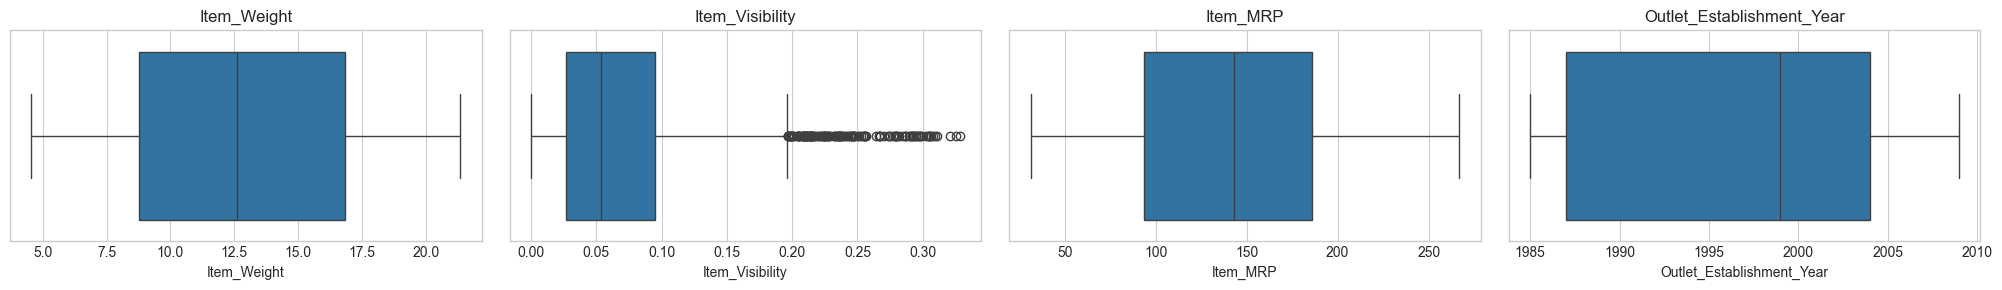

In [128]:
def plot_outliers(df, columns=None, columns_per_row=5, figsize_per_plot=(5, 3)):
    """
    Visualize potential outliers using boxplots.
    """
    if columns is None:
        columns = numerical_features

    columns = [col for col in columns if col in df.columns]

    if not columns:
        print("No numerical features available.")
        return

    rows = (len(columns) + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        sns.boxplot(x=df[column], ax=ax)
        ax.set_title(column)

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    plt.tight_layout()
    save_figure(filename="data_preparation-plot_outliers", fig=fig)
    plt.show()


plot_outliers(df_clean)

**Since the target variable is crucial for regression, let's inspect the outliers in the target column 'salary' before deciding to remove them.**


In [129]:
def handle_outliers_iqr(df, columns=None, multiplier=1.5):
    """
    Remove rows containing IQR-based outliers in selected numerical columns.
    Note: This removes entire rows and can remove legitimate values.
    """
    df = df.copy()

    if columns is None:
        columns = df.select_dtypes(include="number").columns.tolist()

    for column in columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - multiplier * iqr
        upper_bound = q3 + multiplier * iqr

        df = df[
            df[column].between(lower_bound, upper_bound) |
            df[column].isna()
        ]

    return df


print("Since the target variable is crucial for regression, let's inspect the outliers in the target column 'salary' before deciding to remove them. \n")
df_clean_outliers = handle_outliers_iqr(df_clean)
print("Outlier Summary After Handling Outliers:")
display(outlier_summary(df_clean_outliers))

print("Shape after handling outliers:", df_clean_outliers.shape)

Since the target variable is crucial for regression, let's inspect the outliers in the target column 'salary' before deciding to remove them. 

Outlier Summary After Handling Outliers:


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
1,Item_Visibility,-0.072129,0.19173,9,0.11
0,Item_Weight,-3.337500,28.96250,0,0.00
2,Item_MRP,-43.044100,319.68790,0,0.00
3,Outlet_Establishment_Year,1961.500000,2029.50000,0,0.00


Shape after handling outliers: (8193, 12)


### Save Clean Data


In [130]:
save_data(data=df_clean, filename="data_preprocessing-clean_data", index=False)

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\data_preprocessing-clean_data.csv 



WindowsPath('c:/Users/samuel.ablorh/Repository/Data-Workspace/projects/machine-learning/big-mart-sales-prediction/data/processed/data_preprocessing-clean_data.csv')

## Exploratory Data Analysis


### Target Variable Distribution


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-plot_target_distribution.png 



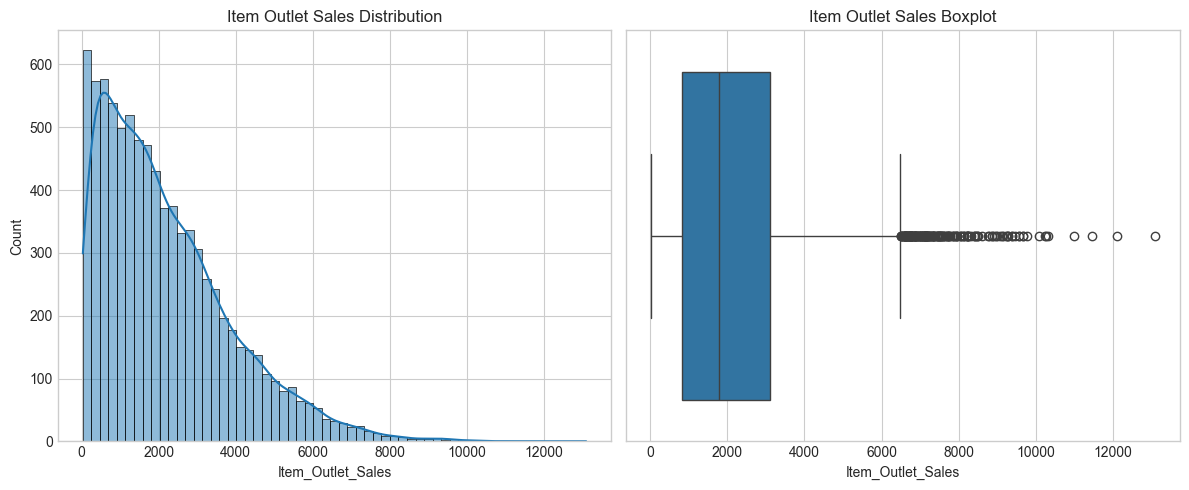

In [39]:
def plot_target_distribution(df, target=TARGET_COLUMN['key'], figsize=(12, 5)):
    """
    Plot the target variable's distribution and boxplot.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    sns.histplot(df[target].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"{TARGET_COLUMN['feature']} Distribution")
    axes[0].set_xlabel(target)

    sns.boxplot(x=df[target], ax=axes[1])
    axes[1].set_title(f"{TARGET_COLUMN['feature']} Boxplot")
    axes[1].set_xlabel(target)

    plt.tight_layout()
    save_figure(filename="eda-plot_target_distribution", fig=fig)
    plt.show()


plot_target_distribution(df_clean, target=TARGET_COLUMN['key'])

In [40]:
def summarize_target_distribution(df, target=TARGET_COLUMN['key']):
    """
    Display descriptive statistics and skewness for the target.
    """
    if target not in df.columns:
        raise ValueError(f"Target column '{target}' not found.")

    df_describe = df[target].describe().to_frame()

    print(f"Target: {target}")
    print(f"Skewness: {df[target].skew():.3f}")
    print("\nDescriptive Statistics:")
    display(df_describe)
    save_table(table=df_describe, filename="eda-target_distribution_summary", index=True)


summarize_target_distribution(df_clean, target=TARGET_COLUMN['key'])

Target: Item_Outlet_Sales
Skewness: 1.178

Descriptive Statistics:


,Item_Outlet_Sales
count,8523.000000
mean,2181.288914
std,1706.499616
min,33.290000
25%,834.247400
50%,1794.331000
75%,3101.296400
max,13086.964800


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\eda-target_distribution_summary.csv 



### Numerical Feature Distributions


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-plot_numerical_distributions.png 



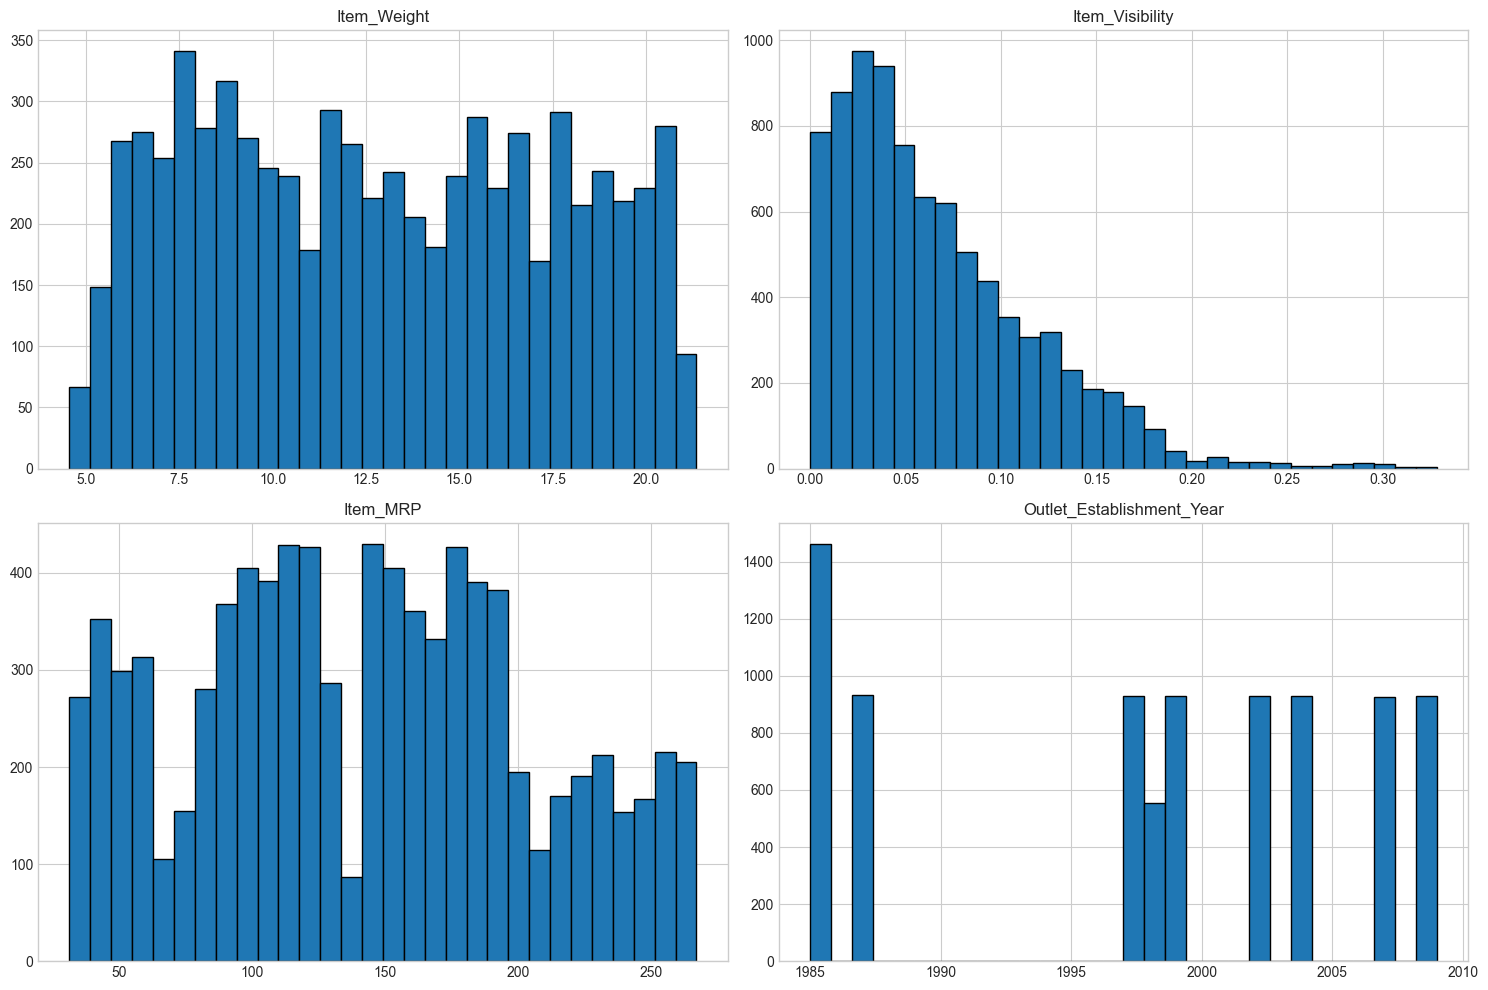

In [41]:
def plot_numerical_distributions(df, exclude=None, columns_per_row=3, figsize=(15, 10)):
    """
    Plot histograms and KDE curves for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    if numeric_df.empty:
        print("No numerical features available.")
        return

    numeric_df.hist(
        bins=30,
        figsize=figsize,
        layout=None,
        edgecolor="black"
    )

    plt.tight_layout()
    save_figure(filename="eda-plot_numerical_distributions")
    
    plt.show()



plot_numerical_distributions(df_clean, exclude=[TARGET_COLUMN['key'], *EXCLUDE_COLUMNS['eda']])

In [42]:
def summarize_numerical_distributions(df, exclude=None):
    """
    Display descriptive statistics and skewness for numerical features.
    """
    numeric_df = df[numerical_features]
    exclude = exclude or []

    numeric_df = numeric_df.drop(
        columns=exclude, errors="ignore"
    )

    summary = numeric_df.describe().T
    summary["skewness"] = numeric_df.skew()
    summary["missing_count"] = numeric_df.isna().sum()

    save_table(table=summary, filename="eda-numerical_distribution_summary", index=True)

    print("Numerical Features Summary: \n")
    display(summary)


summarize_numerical_distributions(df_clean, exclude=[TARGET_COLUMN['key'], *EXCLUDE_COLUMNS['eda']])

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\eda-numerical_distribution_summary.csv 

Numerical Features Summary: 



,count,mean,std,min,25%,50%,75%,max,skewness,missing_count
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000,0.082426,1463
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391,1.167091,0
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400,0.127202,0
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000,-0.396641,0


### Categorical Feature Distributions


Categorical Distributions: 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-plot_categorical_distributions.png 



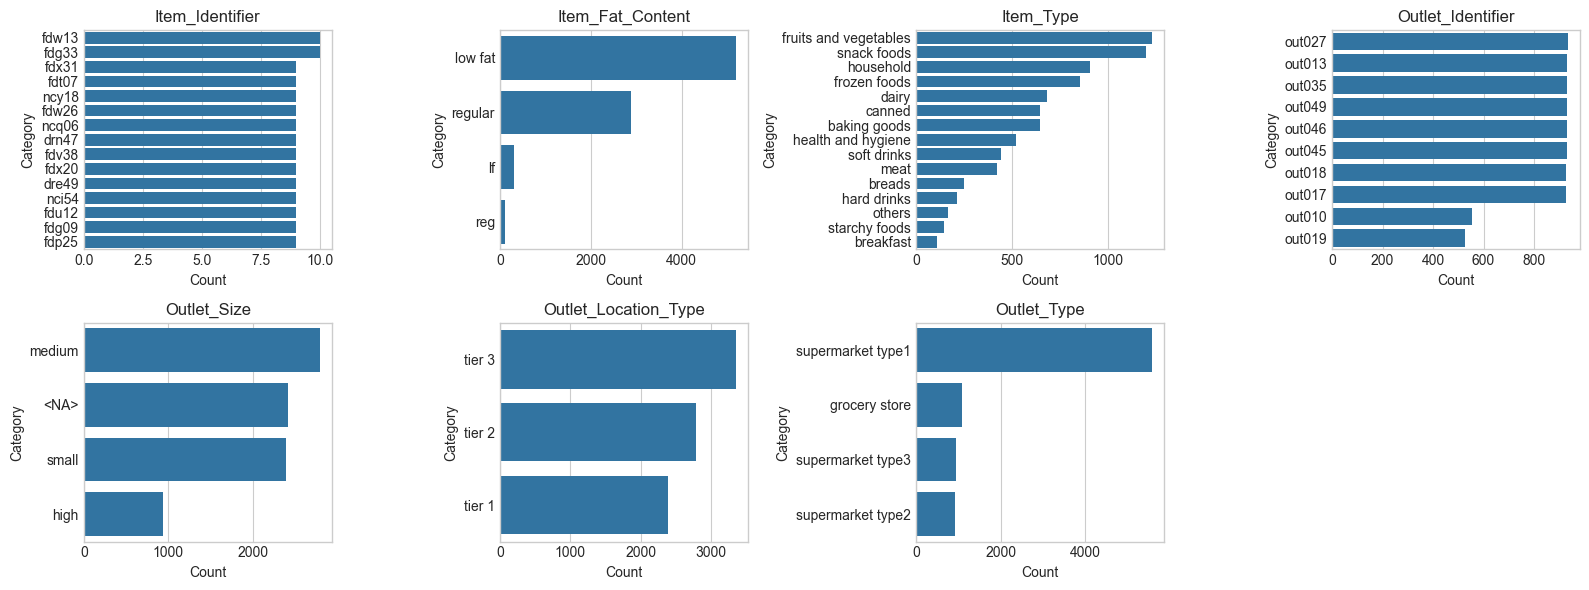

In [43]:
def plot_categorical_distributions(
    df,
    columns=None,
    max_categories=15,
    columns_per_row=4,
    figsize_per_plot=(4, 3)
):
    """
    Plot categorical feature distributions using subplots.
    """
    if columns is None:
        columns = categorical_features

    if not columns:
        print("No categorical features available.")
        return

    n_features = len(columns)
    rows = (n_features + columns_per_row - 1) // columns_per_row

    fig, axes = plt.subplots(
        rows,
        columns_per_row,
        figsize=(
            figsize_per_plot[0] * columns_per_row,
            figsize_per_plot[1] * rows
        ),
        squeeze=False
    )

    for ax, column in zip(axes.flat, columns):
        counts = df[column].value_counts(dropna=False).head(max_categories)

        sns.barplot(
            x=counts.values,
            y=counts.index.astype(str),
            ax=ax
        )
        ax.set_title(column)
        ax.set_xlabel("Count")
        ax.set_ylabel("Category")

    for ax in axes.flat[n_features:]:
        ax.set_visible(False)

    plt.tight_layout()
    save_figure(filename="eda-plot_categorical_distributions", fig=fig)
    plt.show()

print("Categorical Distributions: \n")
plot_categorical_distributions(df_clean)

In [44]:
def summarize_categorical_distributions(df, columns=None):
    """
    Return one table of category counts and percentages.
    """
    if columns is None:
        columns = categorical_features

    summary = []

    for column in columns:
        counts = df[column].value_counts(dropna=False)

        for category, count in counts.items():
            summary.append({
                "feature": column,
                "category": category,
                "count": count,
                "percentage": round(count / len(df) * 100, 2)
            })

    df_summary=pd.DataFrame(summary)

    save_table(table=df_summary, filename="eda-categorical_distribution_summary")

    display(df_summary)


print("Categorical Distributions Summary: \n")
summarize_categorical_distributions(df_clean)

Categorical Distributions Summary: 

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\eda-categorical_distribution_summary.csv 



,feature,category,count,percentage
0,Item_Identifier,fdw13,10,0.12
1,Item_Identifier,fdg33,10,0.12
2,Item_Identifier,fdx31,9,0.11
3,Item_Identifier,fdt07,9,0.11
4,Item_Identifier,ncy18,9,0.11
...,...,...,...,...
1595,Outlet_Location_Type,tier 1,2388,28.02
1596,Outlet_Type,supermarket type1,5577,65.43
1597,Outlet_Type,grocery store,1083,12.71
1598,Outlet_Type,supermarket type3,935,10.97


### Feature–Target Relationships


Feature-Target Relationships: 

Numerical Features vs Target: 
['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year'] 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-plot_numerical_features_vs_target.png 



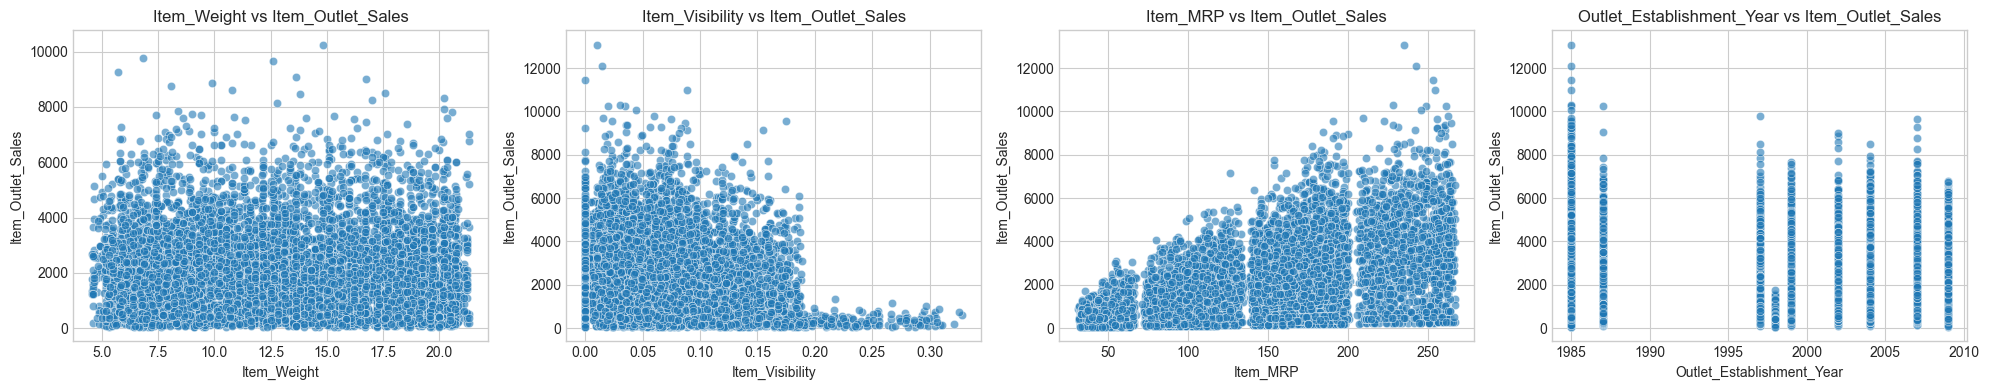

Categorical Features vs Target: 
['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type'] 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-plot_categorical_features_vs_target.png 



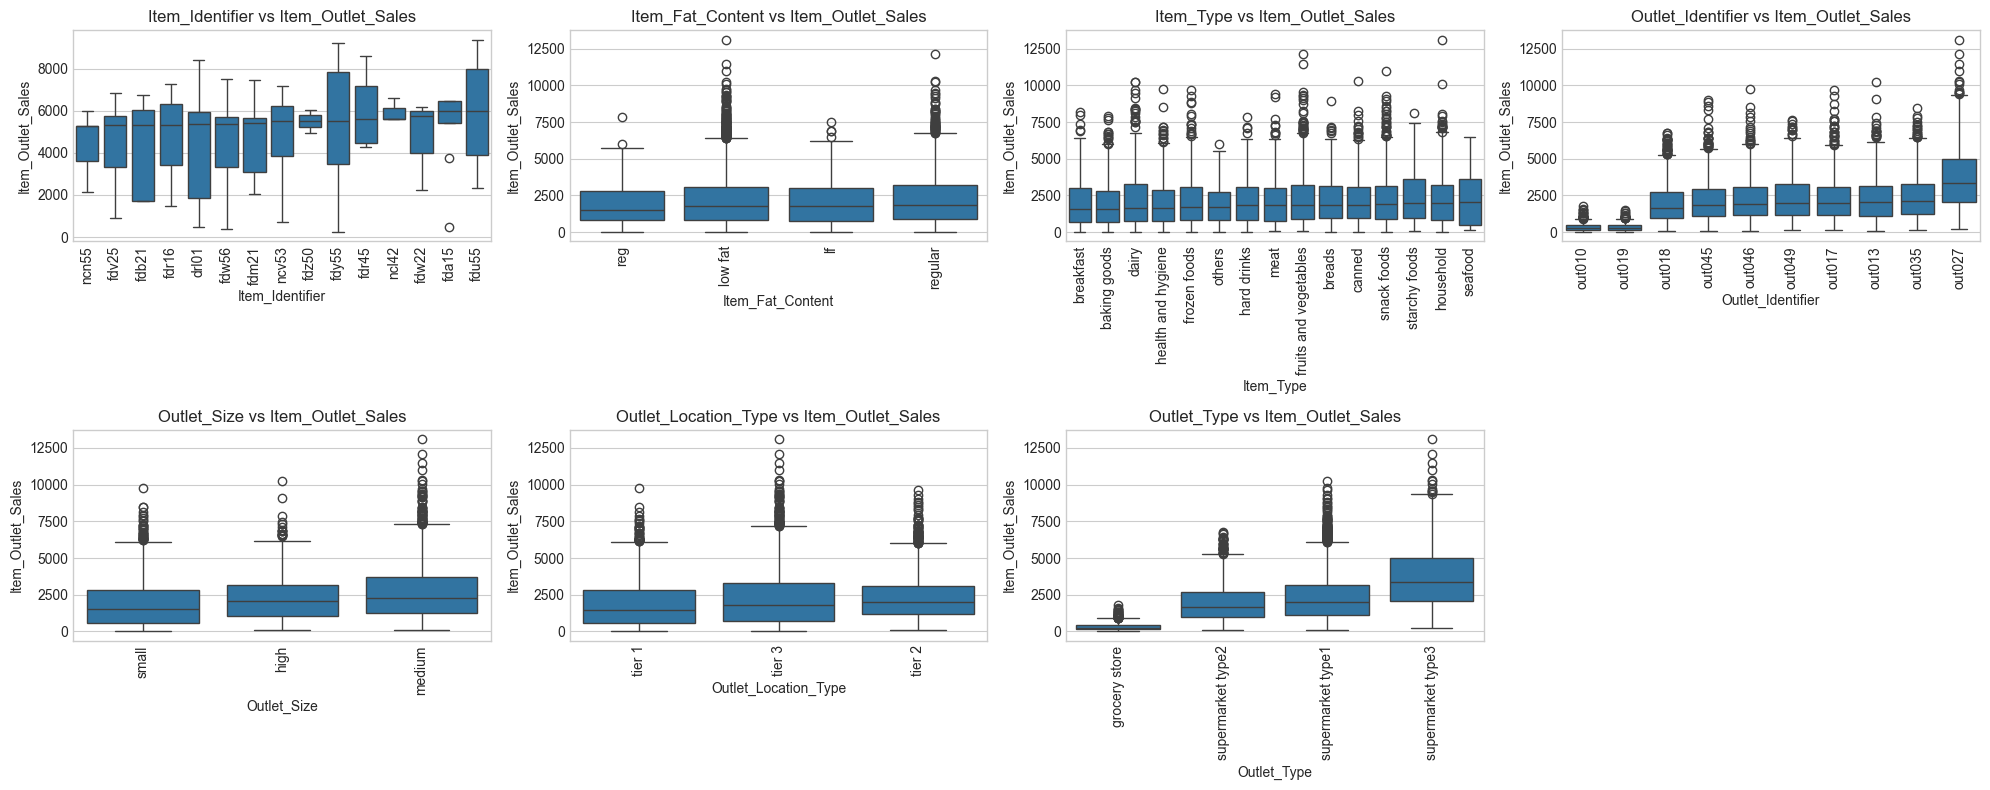

In [45]:
def plot_feature_target_relationships(
    df,
    target=TARGET_COLUMN['key'],
    numerical_columns=None,
    categorical_columns=None,
    columns_per_row=4,
    figsize_per_plot=(5, 4),
    max_categories=15
):
    """
    Plot numerical and categorical feature relationships with the target.
    """
    if numerical_columns is None:
        numerical_columns = numerical_features

    if categorical_columns is None:
        categorical_columns = categorical_features

    numerical_columns = [
        col for col in numerical_columns
        if col != target and col in df.columns
    ]
    categorical_columns = [
        col for col in categorical_columns
        if col != target and col in df.columns
    ]

    print(f"Numerical Features vs Target: \n{numerical_columns} \n")

    # Numerical features vs target
    if numerical_columns:
        rows = (len(numerical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, numerical_columns):
            sns.scatterplot(data=df, x=column, y=target, alpha=0.6, ax=ax)
            ax.set_title(f"{column} vs {target}")

        for ax in axes.flat[len(numerical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        save_figure(filename="eda-plot_numerical_features_vs_target", fig=fig)
        plt.show()

    print(f"Categorical Features vs Target: \n{categorical_columns} \n")

    # Categorical features vs target
    if categorical_columns:
        rows = (len(categorical_columns) + columns_per_row - 1) // columns_per_row

        fig, axes = plt.subplots(
            rows, columns_per_row,
            figsize=(
                figsize_per_plot[0] * columns_per_row,
                figsize_per_plot[1] * rows
            ),
            squeeze=False
        )

        for ax, column in zip(axes.flat, categorical_columns):
            order = (
                df.groupby(column, observed=True)[target]
                .median()
                .sort_values()
                .tail(max_categories)
                .index
            )

            sns.boxplot(
                data=df[df[column].isin(order)],
                x=column,
                y=target,
                order=order,
                ax=ax
            )
            ax.set_title(f"{column} vs {target}")
            ax.tick_params(axis="x", rotation=90)

        for ax in axes.flat[len(categorical_columns):]:
            ax.set_visible(False)

        plt.tight_layout()
        save_figure(filename="eda-plot_categorical_features_vs_target", fig=fig)
        plt.show()

print("Feature-Target Relationships: \n")
plot_feature_target_relationships(df_clean)

### Correlation Analysis


Display a correlation heatmap and features most correlated with the target. 

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\eda-correlation_heatmap.png 



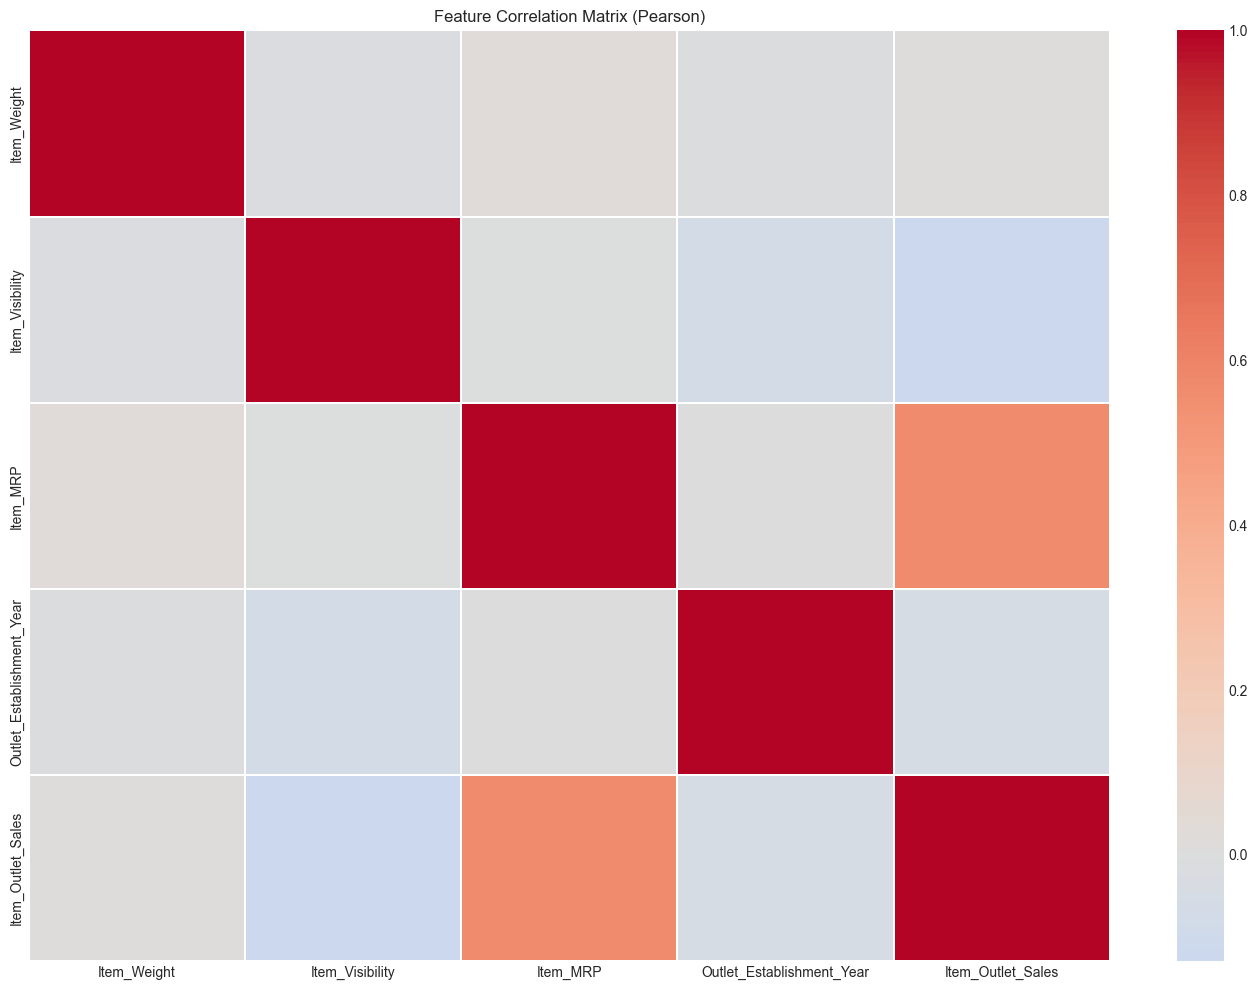

Top 20 features correlated with Item_Outlet_Sales:
Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\eda-target_correlation_table.csv 



,correlation_with_target
Item_MRP,0.567574
Item_Visibility,-0.128625
Outlet_Establishment_Year,-0.049135
Item_Weight,0.014123


In [46]:
def correlation_analysis(
    df,
    target=TARGET_COLUMN['key'],
    method="pearson",
    top_n=20,
    figsize=(14, 10)
):
    """
    Display a correlation heatmap and features most correlated with the target.
    """

    print("Display a correlation heatmap and features most correlated with the target. \n")

    numeric_df = df.select_dtypes(include="number").drop(
        columns=["Id"], errors="ignore"
    )

    correlations = numeric_df.corr(method=method)

    # Correlation heatmap
    fig = plt.figure(figsize=figsize)
    sns.heatmap(
        correlations,
        cmap="coolwarm",
        center=0,
        linewidths=0.3
    )
    plt.title(f"Feature Correlation Matrix ({method.title()})")
    plt.tight_layout()
    save_figure(filename="eda-correlation_heatmap", fig=fig)
    plt.show()

    # Features most correlated with the target
    if target in correlations.columns:
        target_corr = (
            correlations[target]
            .drop(target)
            .dropna()
            .sort_values(key=abs, ascending=False)
            .head(top_n)
            .to_frame("correlation_with_target")
        )

        print(f"Top {top_n} features correlated with {target}:")

        save_table(table=target_corr, filename="eda-target_correlation_table", index=True)
        display(target_corr)


correlation_analysis(df_clean)

### Outlier Investigation


In [48]:
print("Outlier Summary:")  
save_table(table=outlier_summary(df_clean), filename="eda-outlier_summary")
display(outlier_summary(df_clean))

Outlier Summary:
Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\eda-outlier_summary.csv 



,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
1,Item_Visibility,-0.074404,0.195979,144,1.69
0,Item_Weight,-3.340625,28.964375,0,0.00
2,Item_MRP,-43.899300,323.369500,0,0.00
3,Outlet_Establishment_Year,1961.500000,2029.500000,0,0.00


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\data_preparation-plot_outliers.png 



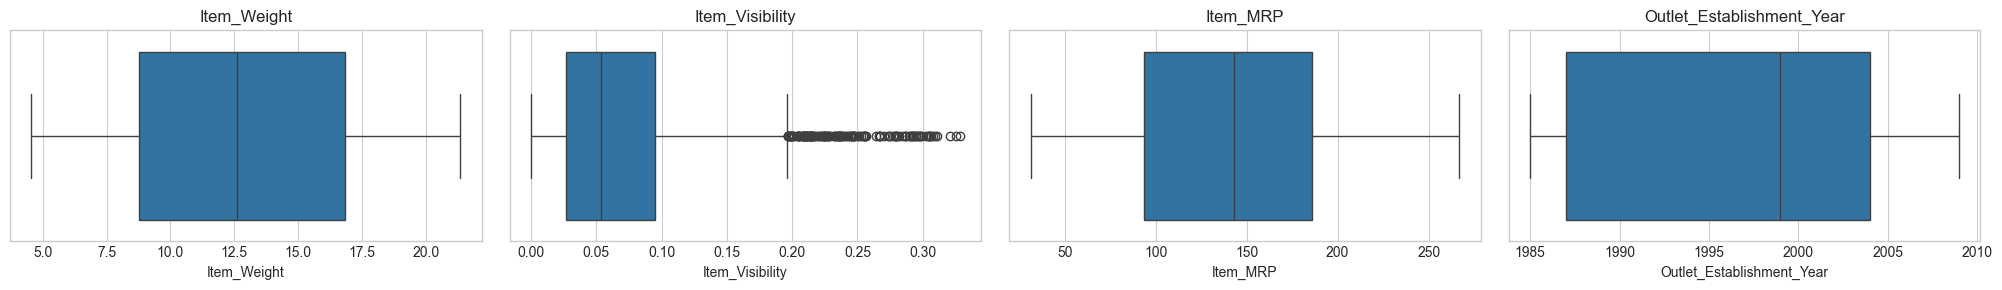

In [49]:
plot_outliers(df_clean)

## Data Spliting


In [615]:
df_working = df_clean.copy()

### Split Data


In [616]:
# Separate features and target.
X = df_working.drop(columns=[TARGET_COLUMN['key']], errors="ignore")
y = df_working[TARGET_COLUMN['key']]

# Split into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=TEST_SIZE,random_state=RANDOM_STATE)

print(f"X_train Shape: {X_train.shape} \n")
print(f"X_test Shape: {X_test.shape} \n")
print(f"y_train Shape: {y_train.shape} \n")
print(f"y_test Shape: {y_test.shape} \n")


save_data(data=X_train, filename="data_preprocessing-x_train_raw")
save_data(data=X_test, filename="data_preprocessing-x_test_raw")
save_data(data=y_train, filename="data_preprocessing-y_train_raw")
save_data(data=y_test, filename="data_preprocessing-y_test_raw")

X_train Shape: (6818, 11) 

X_test Shape: (1705, 11) 

y_train Shape: (6818,) 

y_test Shape: (1705,) 

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\data_preprocessing-x_train_raw.csv 

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\data_preprocessing-x_test_raw.csv 

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\data_preprocessing-y_train_raw.csv 

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\data_preprocessing-y_test_raw.csv 



WindowsPath('c:/Users/samuel.ablorh/Repository/Data-Workspace/projects/machine-learning/big-mart-sales-prediction/data/processed/data_preprocessing-y_test_raw.csv')

### Sample Data


In [617]:
def sample_training_data(X_train, y_train, sample_size=50_000, random_state=RANDOM_STATE):
    """
    Randomly samples training data when it exceeds the specified sample size,
    keeping the features and target values aligned.

    Returns the sampled or original training features and target values.
    """
    try:
        if len(X_train) != len(y_train):
            raise ValueError("X_train and y_train must contain the same number of rows.")

        if not X_train.index.equals(y_train.index):
            raise ValueError("X_train and y_train must have matching indexes in the same order.")

        if not isinstance(sample_size, int) or isinstance(sample_size, bool) or sample_size <= 0:
            raise ValueError("sample_size must be a positive integer.")

        if len(X_train) > sample_size:
            X_train_sampled = X_train.sample(
                n=sample_size,
                random_state=random_state
            )
            y_train_sampled = y_train.loc[X_train_sampled.index]

            print(f"Training data sampled: {sample_size:,} of {len(X_train):,} rows.")

        else:
            X_train_sampled = X_train.copy()
            y_train_sampled = y_train.copy()

            print(f"Sampling skipped: using all {len(X_train):,} training rows.")

        return X_train_sampled, y_train_sampled

    except (ValueError, TypeError, AttributeError) as error:
        raise type(error)(f"Training data sampling failed: {error}") from error


X_train_sampled, y_train_sampled = sample_training_data(
    X_train=X_train,
    y_train=y_train
)

Sampling skipped: using all 6,818 training rows.


In [618]:
X_train = X_train_sampled
y_train = y_train_sampled

## Feature Engineering


### Feature Creation


In [771]:
class FeatureCreator(BaseEstimator, TransformerMixin):
    """
    Create additional features for the Big Mart Sales Prediction dataset.

    Available features:
        item_visibility_ratio: Product visibility relative to the average
            visibility of products within the same outlet.
    """

    def __init__(self, features_to_create=None, reference_year=2026):
        self.features_to_create = features_to_create
        self.reference_year = reference_year

    def fit(self, X, y=None):
        """Learn statistics required for feature engineering."""
        self.is_fitted_ = True

        if "item_visibility_ratio" in (self.features_to_create or []):
            self.outlet_visibility_mean_ = (
                X.groupby("Outlet_Identifier")["Item_Visibility"]
                .mean()
            )

        return self

    def transform(self, X):
        """Create selected engineered features."""
        X = X.copy()

        features_to_create = self.features_to_create or []

        # Item Visibility Ratio
        if "item_visibility_ratio" in features_to_create:
            outlet_mean = X["Outlet_Identifier"].map(
                self.outlet_visibility_mean_
            )

            X["item_visibility_ratio"] = (
                X["Item_Visibility"] / outlet_mean.replace(0, np.nan)
            )

        return X

### Feature Transformation


In [772]:
# No log transformation for this project 

### Feature Dropper


In [773]:
class FeatureDropper(BaseEstimator, TransformerMixin):
    """Remove specified features after feature engineering."""

    def __init__(self, features_to_drop=None):
        self.features_to_drop = features_to_drop

    def fit(self, X, y=None):
        """Learn nothing; features use fixed row-wise calculations."""
        self.is_fitted_ = True
        return self

    def transform(self, X):
        X = X.copy()
        features = self.features_to_drop or []
        return X.drop(columns=features, errors="ignore")

### Feature Engineering Pipeline


In [774]:
feature_engineering_pipeline = Pipeline([
    ("feature_creation", FeatureCreator(features_to_create=FEATURES_TO_CREATE)),
    ("feature_dropper", FeatureDropper(features_to_drop=[*EXCLUDE_COLUMNS["modeling"]]))
])

## Data Preprocessing


### Create Preprocessor


In [775]:
def create_preprocessor():
    """
    Prepare numerical and categorical features for machine learning.

    Numerical features:
        - Fill missing values with the median.
        - Standardize values to a common scale.

    Categorical features:
        - Fill missing values with the most frequent category.
        - Convert categories into numerical columns using one-hot encoding.
    """


    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=NUMERICAL_IMPUTATION)),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("normalize_missing", FunctionTransformer(
            normalize_missing_values,
            validate=False
        )),
        ("imputer", SimpleImputer(strategy=CATEGORICAL_IMPUTATION)),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numerical", numerical_pipeline, make_column_selector(dtype_include="number")),
            ("categorical", categorical_pipeline, make_column_selector(
                dtype_include=["object", "category", "bool", "string"]
            ))
        ],
        remainder="drop"
    )

### Preprocessor Pipeline


In [776]:
preprocessor_pipeline = create_preprocessor()

## Baseline Model Development


### Create Baseline Model Pipeline


In [777]:
baseline_model_pipeline = Pipeline([
    ("feature_engineering", feature_engineering_pipeline),
    ("preprocessor", preprocessor_pipeline),
    ("model", BASELINE_MODEL)
])

### Train Baseline Model


In [778]:
baseline_model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_creation', ...), ('feature_dropper', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_create,['item_visibility_ratio']
,reference_year,2026
Name,Type,Value


### Evaluate Baseline Model


In [808]:
y_pred = baseline_model_pipeline.predict(X_test)

baseline_metrics = {
    key: config["calculate"](y_test, y_pred)
    for key, config in REGRESSION_METRICS.items()
    if "calculate" in config
}

baseline_results = pd.DataFrame([baseline_metrics])

save_table(table=baseline_results, filename="baseline_model-baseline_results")
print("\nBASELINE TEST-SET RESULTS")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\baseline_model-baseline_results.csv 


BASELINE TEST-SET RESULTS


,RMSE,MAE,R2
0,1067.010252,790.864339,0.581117


### Cross-Validate Baseline Model


In [780]:
# Evaluate the complete pipeline using training data only.
cv_scores = cross_val_score(
    baseline_model_pipeline,
    X_train,
    y_train,
    cv=CROSS_VALIDATION_FOLDS,
    scoring=SCORING_METRIC
)

# Convert negative RMSE scores to positive values.
cv_rmse_scores = -cv_scores

# ============================================================
# DISPLAY BASELINE CROSS-VALIDATION RESULTS
# ============================================================

cv_mean_label = REGRESSION_METRICS["CV_MEAN_RMSE"]["label"]
cv_std_label = REGRESSION_METRICS["CV_RMSE_STD"]["label"]

print(f"{REGRESSION_METRICS['RMSE']['label']} per fold:")
print(cv_rmse_scores)

print(f"{cv_mean_label}: {cv_rmse_scores.mean():,.4f}")
print(f"{cv_std_label}: {cv_rmse_scores.std():,.4f}")

Root Mean Squared Error per fold:
[1126.58230993 1129.07383627 1160.54284463 1147.87516392 1162.72289795]
Mean Cross-Validation RMSE: 1,145.3594
Cross-Validation RMSE Standard Deviation: 15.2063


### Baseline Result Summary


In [810]:
# Baseline Cross-Validation Summary
cv_mean_column = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["result_columns"]["baseline"]

cv_std_column = REGRESSION_METRICS[
    "CV_RMSE_STD"
]["result_columns"]["baseline"]

baseline_results[cv_mean_column] = cv_rmse_scores.mean()
baseline_results[cv_std_column] = cv_rmse_scores.std()

save_table(table=baseline_results, filename="baseline_model-baseline_results_summary")
print("BASELINE RESULTS INCLUDING CROSS-VALIDATION")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\baseline_model-baseline_results_summary.csv 

BASELINE RESULTS INCLUDING CROSS-VALIDATION


,RMSE,MAE,R2,CV_Mean_RMSE,CV_RMSE_Std
0,1067.010252,790.864339,0.581117,1145.359411,15.206287


## Model Improvement


### Multicollinearity Analysis


In [782]:
def analyze_multicollinearity(
    X,
    threshold=CORRELATION_THRESHOLD,
    exclude=None,
):
    """
    Identify numerical feature pairs with high absolute correlation.

    Creates engineered features on a temporary copy and returns
    pairs whose absolute correlation meets the threshold.
    """
    # Create a temporary copy with engineered features.
    X_analysis = FeatureCreator(features_to_create=FEATURES_TO_CREATE).fit_transform(X)

    # Identify numerical features.
    numerical_features, _ = get_feature_types(
        X_analysis,
        exclude=exclude or []
    )

    # Calculate the absolute correlation matrix.
    correlation_matrix = (
        X_analysis[numerical_features]
        .corr()
        .abs()
    )

    # Extract unique feature pairs.
    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    high_correlations = (
        upper_triangle
        .stack()
        .reset_index()
    )

    high_correlations.columns = [
        "Feature 1",
        "Feature 2",
        "Absolute Correlation"
    ]

    # Filter and rank highly correlated pairs.
    high_correlations = (
        high_correlations[
            high_correlations["Absolute Correlation"] >= threshold
        ]
        .sort_values(
            "Absolute Correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )

    return high_correlations


high_correlations = analyze_multicollinearity(
    X_train,
    threshold=CORRELATION_THRESHOLD,
    exclude=[*EXCLUDE_COLUMNS["multicollinearity"]]
)

print("High Correlation Features:")
display(high_correlations)

High Correlation Features:


,Feature 1,Feature 2,Absolute Correlation


### VIF - Multicollinearity


In [783]:
def calculate_vif(df, exclude=None, threshold=VIF_THRESHOLD):
    """
    Calculate VIF after removing constant and linearly dependent features.
    Returns the VIF results and the columns excluded from the calculation.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    numerical_features, _ = get_feature_types(
        df,
        exclude=exclude or []
    )

    X = df[numerical_features].dropna(axis=1, how="all")

    if X.shape[1] < 2:
        raise ValueError("At least two usable numerical features are required.")

    X = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X),
        columns=X.columns,
        index=X.index
    )

    # Remove constant columns.
    X = X.loc[:, X.nunique() > 1]

    # Keep only linearly independent columns.
    independent = []
    excluded = []

    for column in X.columns:
        candidate = X[independent + [column]].to_numpy()

        if np.linalg.matrix_rank(candidate) > len(independent):
            independent.append(column)
        else:
            excluded.append(column)

    X = X[independent]

    if X.shape[1] < 2:
        raise ValueError("Fewer than two independent numerical features remain.")

    results = pd.DataFrame({
        "Feature": X.columns,
        "VIF": [
            variance_inflation_factor(X.to_numpy(), i)
            for i in range(X.shape[1])
        ]
    }).sort_values("VIF", ascending=False).reset_index(drop=True)

    excluded_results = pd.DataFrame({
        "Excluded_Feature": excluded
    })

    features_to_remove = results.loc[
        results["VIF"] > threshold, "Feature"
    ].tolist()

    return results, excluded_results, features_to_remove


vif_results, vif_excluded, vif_features_to_remove = calculate_vif(
    X_train,
    exclude=[*EXCLUDE_COLUMNS["multicollinearity"]],
    threshold=VIF_THRESHOLD
)

save_table(table=vif_results, filename="model_improvement-vif_results")
print("\nVIF Results:")
display(vif_results)

save_table(table=vif_excluded, filename="model_improvement-vif_excluded")
print("\nFeatures excluded from VIF calculation due to exact linear dependence:")
display(vif_excluded)

print("\nFeatures to review for removal based on VIF:")
print(vif_features_to_remove)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-vif_results.csv 


VIF Results:


,Feature,VIF
0,Item_MRP,1.000213
1,Outlet_Establishment_Year,1.000213


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-vif_excluded.csv 


Features excluded from VIF calculation due to exact linear dependence:


,Excluded_Feature



Features to review for removal based on VIF:
[]


### Cramers-V - Categorical multicollinearity


In [784]:
def calculate_cramers_v(df, exclude=None, threshold=CORRELATION_THRESHOLD):
    """
    Calculate Cramér's V for pairs of categorical features.

    Returns:
        results: Cramér's V results.
        excluded_results: Pairs excluded from calculation.
        multicollinear_features: Unique features in highly associated pairs.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not 0 <= threshold <= 1:
        raise ValueError("threshold must be between 0 and 1.")

    _, categorical_features = get_feature_types(
        df,
        exclude=exclude or []
    )

    X = df[categorical_features].copy()

    if len(categorical_features) < 2:
        raise ValueError("At least two categorical features are required.")

    results = []
    excluded = []

    for i, feature_1 in enumerate(categorical_features):
        for feature_2 in categorical_features[i + 1:]:

            pair = X[[feature_1, feature_2]].dropna()

            if pair[feature_1].nunique() < 2 or pair[feature_2].nunique() < 2:
                excluded.append({
                    "Feature_1": feature_1,
                    "Feature_2": feature_2,
                    "Reason": "Constant feature or insufficient variation"
                })
                continue

            contingency_table = pd.crosstab(
                pair[feature_1],
                pair[feature_2]
            )

            chi2 = stats.chi2_contingency(
                contingency_table,
                correction=False
            )[0]

            n = contingency_table.to_numpy().sum()
            rows, cols = contingency_table.shape

            cramers_v = np.sqrt(
                chi2 / (n * min(rows - 1, cols - 1))
            )

            results.append({
                "Feature_1": feature_1,
                "Feature_2": feature_2,
                "Cramers_V": cramers_v
            })

    results = pd.DataFrame(results)

    if not results.empty:
        results = results.sort_values(
            "Cramers_V",
            ascending=False
        ).reset_index(drop=True)

        high_association = results[
            results["Cramers_V"] >= threshold
        ]

        multicollinear_features = sorted(set(
            high_association["Feature_1"].tolist()
            + high_association["Feature_2"].tolist()
        ))
    else:
        multicollinear_features = []

    excluded_results = pd.DataFrame(excluded)

    return results, excluded_results, multicollinear_features

In [785]:
cramers_v_results, cramers_v_excluded, categorical_features_to_review = (
    calculate_cramers_v(
        X_train,
        exclude=[*EXCLUDE_COLUMNS["multicollinearity"]],
        threshold=CORRELATION_THRESHOLD
    )
)

save_table(
    table=cramers_v_results,
    filename="model_improvement-cramers_v_results"
)

print("\nCramér's V Results:")
display(cramers_v_results)

save_table(
    table=cramers_v_excluded,
    filename="model_improvement-cramers_v_excluded"
)

print("\nCramér's V Excluded:")
display(cramers_v_excluded)


print("Categorical features to review:")
print(categorical_features_to_review)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-cramers_v_results.csv 


Cramér's V Results:


,Feature_1,Feature_2,Cramers_V
0,Outlet_Size,Outlet_Location_Type,0.580873
1,Outlet_Size,Outlet_Type,0.556715
2,Outlet_Location_Type,Outlet_Type,0.527988
3,Item_Fat_Content,Outlet_Type,0.019218
4,Item_Fat_Content,Outlet_Size,0.016953
5,Item_Fat_Content,Outlet_Location_Type,0.011662


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-cramers_v_excluded.csv 


Cramér's V Excluded:


""


Categorical features to review:
[]


### RFE

In [786]:
def perform_rfe(
    X,
    y,
    estimator,
    *,
    exclude=None,
    features_to_create=None,
    cv_folds=5,
    min_features_to_select=1,
    step=1,
    scoring="neg_root_mean_squared_error"
):
    """
    Select numerical features using RFECV and a specified estimator.
    Returns feature rankings, excluded features, and features to remove.
    """

    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame.")

    if X.empty:
        raise ValueError("X must not be empty.")

    if estimator is None or not hasattr(estimator, "fit"):
        raise TypeError("estimator must be a valid scikit-learn estimator.")

    if not isinstance(cv_folds, int) or isinstance(cv_folds, bool) or cv_folds < 2:
        raise ValueError("cv_folds must be an integer of at least 2.")

    excluded_columns = exclude or []
    missing_columns = set(excluded_columns) - set(X.columns)

    if missing_columns:
        raise ValueError(
            f"Excluded columns not found in X: {sorted(missing_columns)}"
        )

    # Create a temporary copy with engineered features.
    X_analysis = FeatureCreator(
        features_to_create=features_to_create or []
    ).fit_transform(X.copy())

    # Identify numerical features.
    numerical_features, _ = get_feature_types(
        X_analysis,
        exclude=excluded_columns
    )

    X_rfe = X_analysis[numerical_features].dropna(axis=1, how="all")

    if X_rfe.shape[1] == 0:
        raise ValueError("No usable numerical features remain.")

    X_rfe = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X_rfe),
        columns=X_rfe.columns,
        index=X_rfe.index
    )

    X_rfe = X_rfe.loc[:, X_rfe.nunique() > 1]

    if X_rfe.shape[1] == 0:
        raise ValueError("No non-constant numerical features remain.")

    if len(X_rfe) != len(y):
        raise ValueError("X and y must contain the same number of samples.")

    if pd.isna(y).any():
        raise ValueError("y contains missing values.")

    if not 1 <= min_features_to_select <= X_rfe.shape[1]:
        raise ValueError("min_features_to_select is outside the valid range.")

    if cv_folds > len(X_rfe):
        raise ValueError("cv_folds cannot exceed the number of samples.")

    try:
        selector = RFECV(
            estimator=estimator,
            step=step,
            min_features_to_select=min_features_to_select,
            cv=KFold(
                n_splits=cv_folds,
                shuffle=True,
                random_state=42
            ),
            scoring=scoring,
            n_jobs=-1
        )

        selector.fit(X_rfe, y)

    except Exception as exc:
        raise RuntimeError(f"RFE feature selection failed: {exc}") from exc

    results = pd.DataFrame({
        "Feature": X_rfe.columns,
        "Selected": selector.support_,
        "Ranking": selector.ranking_
    }).sort_values(
        ["Selected", "Ranking"],
        ascending=[False, True]
    ).reset_index(drop=True)

    excluded_results = pd.DataFrame({
        "Excluded_Feature": results.loc[
            ~results["Selected"], "Feature"
        ].tolist()
    })

    features_to_remove = excluded_results["Excluded_Feature"].tolist()

    return results, excluded_results, features_to_remove

rfe_results, rfe_excluded, rfe_features_to_remove = perform_rfe(
    X_train,
    y_train,
    estimator=BASELINE_MODEL,
    exclude=EXCLUDE_COLUMNS["multicollinearity"],
    features_to_create=FEATURES_TO_CREATE,
    cv_folds=CROSS_VALIDATION_FOLDS
)

save_table(rfe_results, filename="model_improvement-rfe_results")
print("RFE Results:")
display(rfe_results)

save_table(rfe_excluded, filename="model_improvement-rfe_excluded")
print("Features excluded by RFE:")
display(rfe_excluded)

print("Features to review for removal:")
print(rfe_features_to_remove)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-rfe_results.csv 

RFE Results:


,Feature,Selected,Ranking
0,Item_MRP,True,1
1,Outlet_Establishment_Year,True,1
2,item_visibility_ratio,True,1


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_improvement-rfe_excluded.csv 

Features excluded by RFE:


,Excluded_Feature


Features to review for removal:
[]


## Regression Models Development


### Regression Model Pipeline


In [791]:
regression_models = {
    name: clone(config["estimator"])
    for name, config in REGRESSION_MODEL_CONFIG.items()
}

regression_pipelines = {}

for name, model in regression_models.items():
    regression_pipelines[name] = Pipeline([
        ("feature_engineering", clone(feature_engineering_pipeline)),
        ("preprocessor", clone(preprocessor_pipeline)),
        ("model", model)
    ])

### Train Regression Models


In [792]:
for name, pipeline in regression_pipelines.items():
    print(f"Training {name}...", flush=True)
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully.", flush=True)

Training Linear Regression...
Linear Regression trained successfully.
Training Ridge...
Ridge trained successfully.
Training Lasso...
Lasso trained successfully.
Training Elastic Net...
Elastic Net trained successfully.
Training Random Forest...
Random Forest trained successfully.
Training Gradient Boosting...
Gradient Boosting trained successfully.
Training KNN...
KNN trained successfully.
Training SVR...
SVR trained successfully.
Training XGBoost...
XGBoost trained successfully.
Training LightGBM...
LightGBM trained successfully.


### Evaluate Regression Models


In [793]:
# Evaluate Regression Models
evaluation_results = []

for name, pipeline in regression_pipelines.items():
    y_pred = pipeline.predict(X_test)

    result = {"Model": name}

    for key, config in REGRESSION_METRICS.items():
        if "calculate" in config:
            result[config["column"]] = config["calculate"](
                y_test, y_pred
            )

    evaluation_results.append(result)

rmse_column = REGRESSION_METRICS["RMSE"]["column"]

improved_model_results = (
    pd.DataFrame(evaluation_results)
    .sort_values(by=rmse_column)
    .reset_index(drop=True)
)

save_table(table=improved_model_results, filename="model_building-improved_models_results")
print("\nIMPROVED MODELS RESULTS")
display(improved_model_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_building-improved_models_results.csv 


IMPROVED MODELS RESULTS


,Model,RMSE,MAE,R2
0,Gradient Boosting,1033.591061,720.484111,0.606945
1,LightGBM,1049.406628,728.955919,0.594825
2,Linear Regression,1067.010252,790.864339,0.581117
3,Ridge,1067.208264,790.955875,0.580962
4,Lasso,1068.686153,791.977617,0.579800
5,Random Forest,1090.054578,758.336754,0.562829
6,XGBoost,1106.715178,770.094365,0.549363
7,KNN,1122.030531,777.546857,0.536804
8,Elastic Net,1269.142695,966.477693,0.407380
9,SVR,1561.229439,1163.830510,0.103214


### Cross-Validate Regression models


In [794]:
# Cross-Validate Improved Models
cv_results = []

cv_scoring = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["scoring"]

cv_mean_column = REGRESSION_METRICS[
    "CV_MEAN_RMSE"
]["result_columns"]["initial_cv"]

cv_std_column = REGRESSION_METRICS[
    "CV_RMSE_STD"
]["result_columns"]["initial_cv"]

for name, pipeline in regression_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CROSS_VALIDATION_FOLDS,
        scoring=cv_scoring,
        n_jobs=-1
    )

    # Convert sklearn's negative RMSE scores to positive RMSE.
    rmse_scores = -scores["test_score"]

    cv_results.append({
        "Model": name,
        cv_mean_column: rmse_scores.mean(),
        cv_std_column: rmse_scores.std()
    })

improved_cv_results = (
    pd.DataFrame(cv_results)
    .sort_values(cv_mean_column)
    .reset_index(drop=True)
)

save_table(table=improved_model_results, filename="model_building-cross_validation_model_improved_results")
print("CROSS-VALIDATION RESULTS")
display(improved_cv_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_building-cross_validation_model_improved_results.csv 

CROSS-VALIDATION RESULTS


,Model,Mean CV RMSE,Std CV RMSE
0,Gradient Boosting,1095.894301,13.416260
1,LightGBM,1128.320682,17.146839
2,Linear Regression,1145.359411,15.206287
3,Ridge,1145.374127,15.153083
4,Lasso,1145.614510,14.898301
5,Random Forest,1164.879923,6.737449
6,XGBoost,1191.068858,13.483831
7,KNN,1198.701584,13.361311
8,Elastic Net,1338.176480,11.858586
9,SVR,1672.760264,23.896756


## Hyperparameter Tuning


#### Model Params


In [795]:
param_grids = {
    name: config["param_grid"]
    for name, config in REGRESSION_MODEL_CONFIG.items()
}

#### Hyperparameter Tunning


In [796]:
def tune_regression_models(
    regression_pipelines,
    param_grids,
    X_train,
    y_train,
    cv=CROSS_VALIDATION_FOLDS,
    scoring=None
):
    """
    Tune multiple regression pipelines using GridSearchCV.
    Selects the best hyperparameters for each model through cross-validation,
    evaluates models using the specified scoring metric, saves and displays
    the tuning results sorted by mean cross-validation RMSE, and returns the
    best fitted models and the tuning results DataFrame.
    """

    if scoring is None:
        scoring = REGRESSION_METRICS["RMSE"]["scoring"]

    best_models = {}
    tuning_results = []

    tuned_cv_column = REGRESSION_METRICS[
        "CV_MEAN_RMSE"
    ]["result_columns"]["tuned_cv"]

    for name, pipeline in regression_pipelines.items():

        print(f"\nTuning model: {name}")

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            refit=True
        )

        grid_search.fit(X_train, y_train)

        best_models[name] = grid_search.best_estimator_

        tuning_results.append({
            "Model": name,
            tuned_cv_column: -grid_search.best_score_,
            "Best Parameters": grid_search.best_params_
        })

        print(
            f"{tuned_cv_column}: "
            f"{-grid_search.best_score_:,.2f}"
        )
        print(f"Best Parameters: {grid_search.best_params_}")

    tuning_results_df = (
        pd.DataFrame(tuning_results)
        .sort_values(tuned_cv_column)
        .reset_index(drop=True)
    )

    save_table(table=tuning_results_df, filename="hyperparameter_tuning-model_tuning_results")
    print("\nHYPERPARAMETER TUNING RESULTS")
    display(tuning_results_df)

    return best_models, tuning_results_df


# ============================================================
# EXECUTE HYPERPARAMETER TUNING
# ============================================================

best_models, tuning_results_df = tune_regression_models(
    regression_pipelines=regression_pipelines,
    param_grids=param_grids,
    X_train=X_train,
    y_train=y_train
)


Tuning model: Linear Regression
Best CV RMSE: 1,145.36
Best Parameters: {'model__fit_intercept': True}

Tuning model: Ridge
Best CV RMSE: 1,145.36
Best Parameters: {'model__alpha': 0.1}

Tuning model: Lasso
Best CV RMSE: 1,145.61
Best Parameters: {'model__alpha': 1.0, 'model__max_iter': 20000}

Tuning model: Elastic Net
Best CV RMSE: 1,153.47
Best Parameters: {'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}

Tuning model: Random Forest
Best CV RMSE: 1,113.28
Best Parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Tuning model: Gradient Boosting
Best CV RMSE: 1,092.50
Best Parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}

Tuning model: KNN
Best CV RMSE: 1,137.11
Best Parameters: {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}

Tuning model: SVR
Best CV RMSE: 1,131.73
Best Parameters: {'model__C': 100, 'model__epsilon': 0.2, 'model__kernel': 'rbf'}

Tun

,Model,Best CV RMSE,Best Parameters
0,XGBoost,1091.525309,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_e..."
1,Gradient Boosting,1092.503354,"{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}"
2,LightGBM,1094.499392,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_..."
3,Random Forest,1113.283305,"{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}"
4,SVR,1131.728754,"{'model__C': 100, 'model__epsilon': 0.2, 'model__kernel': 'rbf'}"
5,KNN,1137.108418,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}"
6,Ridge,1145.358828,{'model__alpha': 0.1}
7,Linear Regression,1145.359411,{'model__fit_intercept': True}
8,Lasso,1145.614510,"{'model__alpha': 1.0, 'model__max_iter': 20000}"
9,Elastic Net,1153.469755,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}"


#### Evaluate Tuned Models


In [797]:
def evaluate_tuned_models(best_models, X_test, y_test):
    """
    Evaluate tuned regression models on the test set using the configured
    regression metrics, sort the results by RMSE in ascending order, save
    and display the evaluation results, and return the results DataFrame.
    """

    results = []

    for name, pipeline in best_models.items():
        y_pred = pipeline.predict(X_test)

        result = {"Model": name}

        for key, config in REGRESSION_METRICS.items():
            if "calculate" in config:
                result[config["column"]] = config["calculate"](
                    y_test, y_pred
                )

        results.append(result)

    rmse_column = REGRESSION_METRICS["RMSE"]["column"]

    results_df = (
        pd.DataFrame(results)
        .sort_values(rmse_column)
        .reset_index(drop=True)
    )

    save_table(table=results_df, filename="hyperparameter_tuning-final_test_set_evaluation_results")

    print("FINAL TEST-SET EVALUATION RESULTS")
    display(results_df)

    return results_df


final_test_results = evaluate_tuned_models(
    best_models=best_models,
    X_test=X_test,
    y_test=y_test
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\hyperparameter_tuning-final_test_set_evaluation_results.csv 

FINAL TEST-SET EVALUATION RESULTS


,Model,RMSE,MAE,R2
0,XGBoost,1020.889227,718.548376,0.616547
1,LightGBM,1021.500313,716.020270,0.616087
2,Gradient Boosting,1028.111133,718.486847,0.611102
3,Random Forest,1041.148184,727.930027,0.601177
4,SVR,1043.153602,725.229592,0.599639
5,KNN,1057.272408,735.342357,0.588728
6,Linear Regression,1067.010252,790.864339,0.581117
7,Ridge,1067.030273,790.872423,0.581101
8,Lasso,1068.686153,791.977617,0.579800
9,Elastic Net,1077.924817,795.476606,0.572504


## Finalist Models


### Comparism Table


In [812]:
def create_regression_comparison(
    improved_model_results,
    improved_cv_results,
    tuning_results_df,
    final_test_results
):

    """
    Consolidates initial model evaluation, cross-validation, hyperparameter tuning,
    and final test results into a single comparison DataFrame. Renames metric columns,
    merges results by model, orders columns, sorts models by tuned cross-validation RMSE,
    saves the comparison table, and displays the final results.
    """

    # 1. Rename metric columns using the configuration.
    initial_test_renames = {
        config["column"]: config["comparison_columns"]["initial_test"]
        for config in REGRESSION_METRICS.values()
        if "initial_test" in config.get("comparison_columns", {})
        and "calculate" in config
    }

    initial_cv_renames = {
        "Mean CV RMSE": "Initial CV RMSE",
        "Std CV RMSE": "Initial CV RMSE Std"
    }

    tuned_cv_renames = {
        "Best CV RMSE": REGRESSION_METRICS["RMSE"]["comparison_columns"]["tuned_cv"]
    }

    final_test_renames = {
        config["column"]: config["comparison_columns"]["final_test"]
        for config in REGRESSION_METRICS.values()
        if "final_test" in config.get("comparison_columns", {})
        and "calculate" in config
    }

    improved_results = improved_model_results.rename(columns=initial_test_renames)
    improved_cv = improved_cv_results.rename(columns=initial_cv_renames)
    tuned_results = tuning_results_df.rename(columns=tuned_cv_renames)
    final_results = final_test_results.rename(columns=final_test_renames)

    # 2. Combine results by model.
    comparison_df = (
        improved_results
        .merge(improved_cv, on="Model", how="outer")
        .merge(tuned_results, on="Model", how="outer")
        .merge(final_results, on="Model", how="outer")
    )

    # 3. Arrange columns in the original order.
    preferred_columns = PREFERRED_METRICS_COLUMNS

    comparison_df = comparison_df[
        [col for col in preferred_columns if col in comparison_df.columns]
    ].sort_values(
        by="Tuned CV RMSE",
        na_position="last"
    ).reset_index(drop=True)

    save_table(table=comparison_df, filename="final_model-models_comparism")

    print("CONSOLIDATED REGRESSION MODEL COMPARISON")
    display(comparison_df)

    return comparison_df


# ============================================================
# EXECUTE COMPARISON
# ============================================================

regression_comparison_df = create_regression_comparison(
    improved_model_results=improved_model_results,
    improved_cv_results=improved_cv_results,
    tuning_results_df=tuning_results_df,
    final_test_results=final_test_results
)

print("BASELINE MODEL RESULTS")
display(baseline_results)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\final_model-models_comparism.csv 

CONSOLIDATED REGRESSION MODEL COMPARISON


,Model,Initial CV RMSE,Initial CV RMSE Std,Initial Test RMSE,Initial Test MAE,Initial Test R2,Tuned CV RMSE,Tuned Test RMSE,Tuned Test MAE,Tuned Test R2,Best Parameters
0,XGBoost,1191.068858,13.483831,1106.715178,770.094365,0.549363,1091.525309,1020.889227,718.548376,0.616547,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_e..."
1,Gradient Boosting,1095.894301,13.416260,1033.591061,720.484111,0.606945,1092.503354,1028.111133,718.486847,0.611102,"{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}"
2,LightGBM,1128.320682,17.146839,1049.406628,728.955919,0.594825,1094.499392,1021.500313,716.020270,0.616087,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_..."
3,Random Forest,1164.879923,6.737449,1090.054578,758.336754,0.562829,1113.283305,1041.148184,727.930027,0.601177,"{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}"
4,SVR,1672.760264,23.896756,1561.229439,1163.830510,0.103214,1131.728754,1043.153602,725.229592,0.599639,"{'model__C': 100, 'model__epsilon': 0.2, 'model__kernel': 'rbf'}"
5,KNN,1198.701584,13.361311,1122.030531,777.546857,0.536804,1137.108418,1057.272408,735.342357,0.588728,"{'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}"
6,Ridge,1145.374127,15.153083,1067.208264,790.955875,0.580962,1145.358828,1067.030273,790.872423,0.581101,{'model__alpha': 0.1}
7,Linear Regression,1145.359411,15.206287,1067.010252,790.864339,0.581117,1145.359411,1067.010252,790.864339,0.581117,{'model__fit_intercept': True}
8,Lasso,1145.614510,14.898301,1068.686153,791.977617,0.579800,1145.614510,1068.686153,791.977617,0.579800,"{'model__alpha': 1.0, 'model__max_iter': 20000}"
9,Elastic Net,1338.176480,11.858586,1269.142695,966.477693,0.407380,1153.469755,1077.924817,795.476606,0.572504,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8, 'model__max_iter': 20000}"


BASELINE MODEL RESULTS


,RMSE,MAE,R2,CV_Mean_RMSE,CV_RMSE_Std
0,1067.010252,790.864339,0.581117,1145.359411,15.206287


### Model Selection


In [799]:
def select_best_regression_model(comparison_df):
    """
    Select the best regression model.

    Primary criterion:
        Lowest mean tuned cross-validation RMSE.

    Secondary criterion:
        Lowest tuned CV RMSE standard deviation, if available.

    Test metrics are for final evaluation, not model selection.
    """

    # Get the configured primary metric
    metric_config = REGRESSION_METRICS["RMSE"]
    selection_column = metric_config["comparison_columns"]["tuned_cv"]

    if selection_column not in comparison_df.columns:
        raise ValueError(
            f"Missing selection column: {selection_column!r}"
        )

    candidates = comparison_df.copy()

    candidates[selection_column] = pd.to_numeric(
        candidates[selection_column], errors="coerce"
    )

    candidates = candidates.replace([np.inf, -np.inf], np.nan)
    candidates = candidates.dropna(subset=[selection_column])
    candidates = candidates[candidates[selection_column] >= 0]

    if candidates.empty:
        raise ValueError(
            f"No valid values found in {selection_column!r}."
        )

    # Primary ranking: lowest tuned CV RMSE
    sort_columns = [selection_column]
    ascending = [True]

    # Secondary ranking: CV RMSE standard deviation, if available
    std_column = REGRESSION_METRICS["CV_RMSE_STD"]["column"]

    if std_column in candidates.columns:
        candidates[std_column] = pd.to_numeric(
            candidates[std_column], errors="coerce"
        )
        sort_columns.append(std_column)
        ascending.append(True)

    ranked = candidates.sort_values(
        by=sort_columns,
        ascending=ascending,
        na_position="last",
    )

    best_model = ranked.iloc[0]

    # Display available results
    display_columns = [
        col for col in PREFERRED_METRICS_COLUMNS
        if col in ranked.columns
    ]

    summary = best_model[display_columns].to_frame(name="Value")

    save_table(
        table=summary,
        filename="final_model-best_regression_model_summary",
    )

    print("BEST REGRESSION MODEL")
    display(summary)

    print("\nTOP 3 MODELS BY TUNED CV RMSE")
    display(ranked[display_columns].head(3))

    return best_model


# ============================================================
# EXECUTE MODEL SELECTION
# ============================================================

best_model_result = select_best_regression_model(
    comparison_df=regression_comparison_df
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\final_model-best_regression_model_summary.csv 

BEST REGRESSION MODEL


,Value
Model,XGBoost
Initial CV RMSE,1191.068858
Initial CV RMSE Std,13.483831
Initial Test RMSE,1106.715178
Initial Test MAE,770.094365
Initial Test R2,0.549363
Tuned CV RMSE,1091.525309
Tuned Test RMSE,1020.889227
Tuned Test MAE,718.548376
Tuned Test R2,0.616547



TOP 3 MODELS BY TUNED CV RMSE


,Model,Initial CV RMSE,Initial CV RMSE Std,Initial Test RMSE,Initial Test MAE,Initial Test R2,Tuned CV RMSE,Tuned Test RMSE,Tuned Test MAE,Tuned Test R2,Best Parameters
0,XGBoost,1191.068858,13.483831,1106.715178,770.094365,0.549363,1091.525309,1020.889227,718.548376,0.616547,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_e..."
1,Gradient Boosting,1095.894301,13.416260,1033.591061,720.484111,0.606945,1092.503354,1028.111133,718.486847,0.611102,"{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}"
2,LightGBM,1128.320682,17.146839,1049.406628,728.955919,0.594825,1094.499392,1021.500313,716.020270,0.616087,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_..."


### Retrive Best Model


In [800]:
# ============================================================
# RETRIEVE THE BEST REGRESSION MODEL
# ============================================================

def get_best_regression_model(best_model_result, best_models):
    model_name = best_model_result["Model"]
    model = best_models[model_name]

    print(f"Selected Model: {model_name}")
    print("Retrieved fitted pipeline successfully.")

    return model


# ============================================================
# EXECUTE
# ============================================================

best_model = get_best_regression_model(
    best_model_result=best_model_result,
    best_models=best_models
)

best_model

Selected Model: XGBoost
Retrieved fitted pipeline successfully.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_creation', ...), ('feature_dropper', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_create,['item_visibility_ratio']
,reference_year,2026
Name,Type,Value


### Evaluate Best Model


In [801]:
def evaluate_best_model(best_model_result, final_test_results):
    model_name = best_model_result["Model"]

    results = final_test_results.loc[
        final_test_results["Model"] == model_name
    ]

    save_table(table=results.reset_index(drop=True), filename="final_model-best_model_performance")

    print(f"PERFORMANCE OF THE BEST MODEL: {model_name}")
    display(results.reset_index(drop=True))

    return results


# ============================================================
# EXECUTE EVALUATION
# ============================================================

best_model_evaluation = evaluate_best_model(
    best_model_result=best_model_result,
    final_test_results=final_test_results
)

Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\final_model-best_model_performance.csv 

PERFORMANCE OF THE BEST MODEL: XGBoost


,Model,RMSE,MAE,R2
0,XGBoost,1020.889227,718.548376,0.616547


## Model Diagnostics


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_diagnostics-best_model_diagnostics.csv 

MODEL DIAGNOSTICS: XGBoost

Residual Summary Statistics


,Residuals
count,1705.000000
mean,-20.497153
std,1020.982890
min,-3808.609023
25%,-516.540632
50%,-67.563626
75%,428.874667
max,5624.042107


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_diagnostics-residuals_vs_predicted.png 



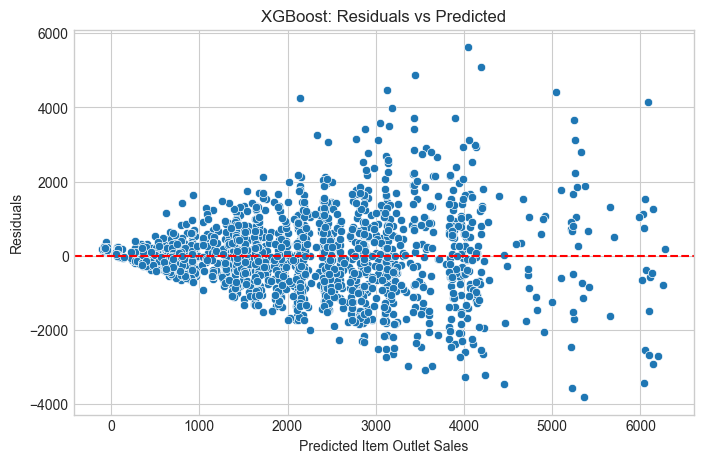

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_diagnostics-residual_distribution.png 



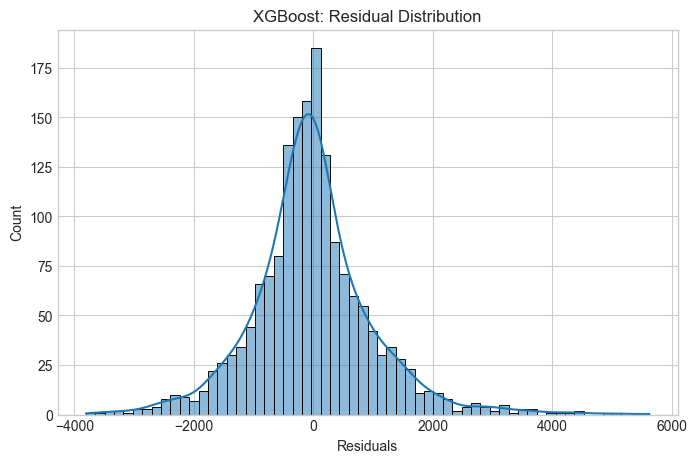

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_diagnostics-normal_qq_plot.png 



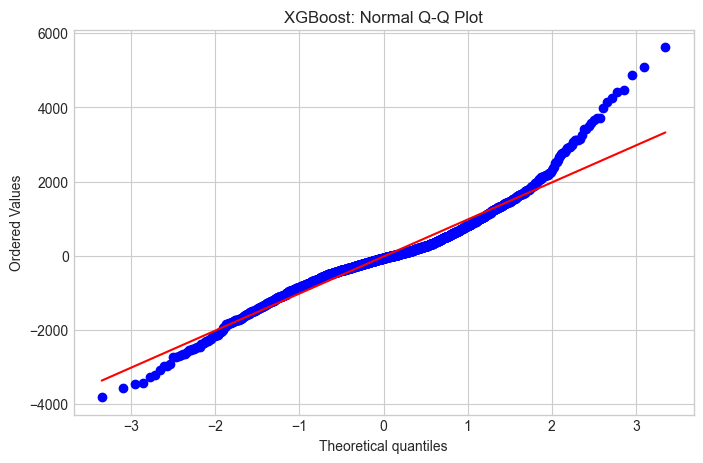

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_diagnostics-residuals_vs_actual.png 



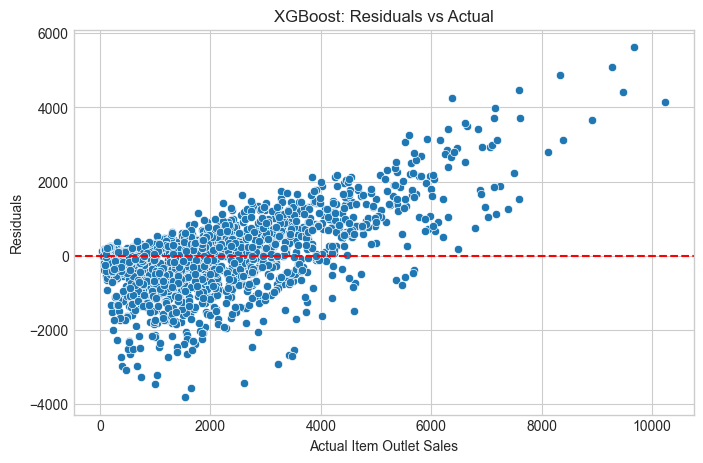

Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_diagnostics-actual_vs_predicted.png 



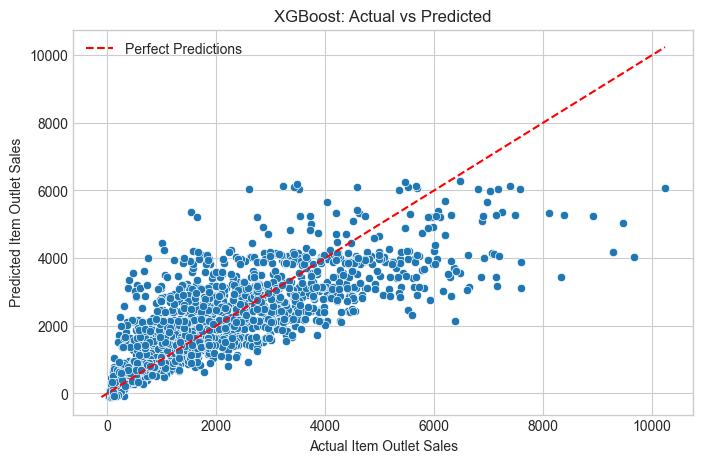

In [802]:
def diagnose_regression_model(
    best_model,
    best_model_result,
    X_test,
    y_test,
    model_config
):
    """
    Generates diagnostic statistics and plots for the selected regression model using test data. 
    
    Calculates predictions and residuals, displays and saves residual summary statistics, 
    and generates only the diagnostic plots specified in the model configuration to evaluate prediction accuracy, 
    residual distribution, normality, and error patterns. 
    
    Returns a DataFrame containing actual values, predicted values, and residuals.
    """
    # 1. Identify the selected model.
    model_name = best_model_result["Model"]

    # 2. Retrieve its diagnostic configuration.
    diagnostics = model_config[model_name]["model_diagnostics"]

    # 3. Generate predictions and calculate residuals.
    y_pred = best_model.predict(X_test)

    y_actual = pd.Series(y_test).reset_index(drop=True)
    y_pred = pd.Series(y_pred).reset_index(drop=True)
    residuals = y_actual - y_pred

    # 4. Prepare diagnostic data.
    diagnostic_df = pd.DataFrame({
        "Actual": y_actual,
        "Predicted": y_pred,
        "Residuals": residuals
    })

    save_table(table=diagnostic_df["Residuals"].describe().to_frame(), filename="model_diagnostics-best_model_diagnostics", index=True)

    print(f"MODEL DIAGNOSTICS: {model_name}")
    print("\nResidual Summary Statistics")
    display(diagnostic_df["Residuals"].describe().to_frame())

    # 5. Generate only the configured diagnostics.
    for diagnostic in diagnostics:

        if diagnostic == "residuals_vs_predicted":
            fig = plt.figure(figsize=(8, 5))
            sns.scatterplot(
                x=diagnostic_df["Predicted"],
                y=diagnostic_df["Residuals"]
            )
            plt.axhline(0, color="red", linestyle="--")
            plt.title(f"{model_name}: Residuals vs Predicted")
            plt.xlabel(f"Predicted {TARGET_COLUMN['feature']}")
            plt.ylabel("Residuals")
            save_figure(filename="model_diagnostics-residuals_vs_predicted", fig=fig)
            plt.show()

        elif diagnostic == "residual_distribution":
            fig = plt.figure(figsize=(8, 5))
            sns.histplot(
                diagnostic_df["Residuals"],
                kde=True
            )
            plt.title(f"{model_name}: Residual Distribution")
            plt.xlabel("Residuals")
            save_figure(filename="model_diagnostics-residual_distribution", fig=fig)
            plt.show()

        elif diagnostic == "normal_qq_plot":
            fig = plt.figure(figsize=(8, 5))
            stats.probplot(
                diagnostic_df["Residuals"],
                dist="norm",
                plot=plt
            )
            plt.title(f"{model_name}: Normal Q-Q Plot")
            save_figure(filename="model_diagnostics-normal_qq_plot", fig=fig)
            plt.show()

        elif diagnostic == "residuals_vs_actual":
            fig = plt.figure(figsize=(8, 5))
            sns.scatterplot(
                x=diagnostic_df["Actual"],
                y=diagnostic_df["Residuals"]
            )
            plt.axhline(0, color="red", linestyle="--")
            plt.title(f"{model_name}: Residuals vs Actual")
            plt.xlabel(f"Actual {TARGET_COLUMN['feature']}")
            plt.ylabel("Residuals")
            save_figure(filename="model_diagnostics-residuals_vs_actual", fig=fig)
            plt.show()

        elif diagnostic == "actual_vs_predicted":
            fig, ax = plt.subplots(figsize=(8, 5))

            sns.scatterplot(
                x=diagnostic_df["Actual"],
                y=diagnostic_df["Predicted"],
                ax=ax
            )

            # Perfect prediction reference line.
            min_value = min(
                diagnostic_df["Actual"].min(),
                diagnostic_df["Predicted"].min()
            )
            max_value = max(
                diagnostic_df["Actual"].max(),
                diagnostic_df["Predicted"].max()
            )

            ax.plot(
                [min_value, max_value],
                [min_value, max_value],
                color="red",
                linestyle="--",
                label="Perfect Predictions"
            )

            ax.set_title(f"{model_name}: Actual vs Predicted")
            ax.set_xlabel(f"Actual {TARGET_COLUMN['feature']}")
            ax.set_ylabel(f"Predicted {TARGET_COLUMN['feature']}")
            ax.legend()

            save_figure(
                filename="model_diagnostics-actual_vs_predicted",
                fig=fig
            )

            plt.show()

        else:
            print(f"Unrecognized diagnostic skipped: {diagnostic}")

    return diagnostic_df


# ============================================================
# EXECUTE MODEL DIAGNOSTICS
# ============================================================

best_model_diagnostics = diagnose_regression_model(
    best_model=best_model,
    best_model_result=best_model_result,
    X_test=X_test,
    y_test=y_test,
    model_config=REGRESSION_MODEL_CONFIG
)

## Model Interpretation


Table saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\tables\model_interpretation-feature_importance.csv 

FEATURE IMPORTANCE: XGBoost


,Feature,Importance,Importance Std
0,Item_MRP,711.186448,34.650361
1,Outlet_Type,574.781141,26.722411
2,Outlet_Establishment_Year,1.788415,0.775117
3,Outlet_Identifier,0.610236,0.228139
4,Item_Fat_Content,0.018275,0.232555
5,Item_Weight,0.000000,0.000000
6,Item_Identifier,0.000000,0.000000
7,Outlet_Location_Type,0.000000,0.000000
8,Item_Type,0.000000,0.000000
9,Item_Visibility,-0.282305,1.229917


Figure saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\outputs\figures\model_interpretation-permutation_feature_importance.png 



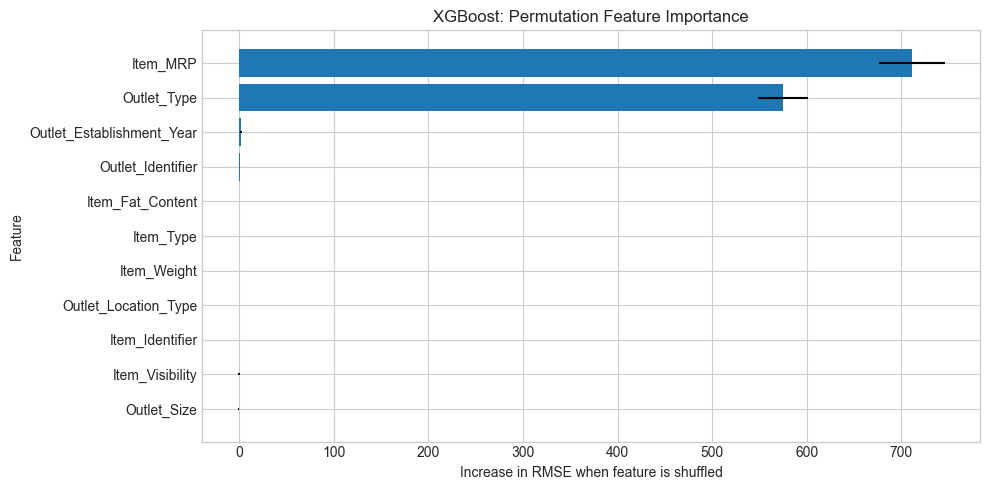

In [803]:
def interpret_regression_model(
    best_model,
    best_model_result,
    X_test,
    y_test,
    random_state=RANDOM_STATE
):
    """
    Calculates and ranks feature importance for the selected regression model
    using permutation importance on the test data.

    Displays and saves a feature importance table containing mean importance
    and standard deviation.

    Generates and saves a bar chart of the top 20 most influential features.

    Returns the sorted feature importance DataFrame.
    """
    # 1. Identify the selected model.
    model_name = best_model_result["Model"]

    # 2. Calculate permutation importance.
    importance = permutation_importance(
        estimator=best_model,
        X=X_test,
        y=y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=random_state,
        n_jobs=-1
    )

    # 3. Build and sort the importance table.
    feature_names = (
        X_test.columns
        if hasattr(X_test, "columns")
        else [f"Feature {i}" for i in range(X_test.shape[1])]
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance.importances_mean,
        "Importance Std": importance.importances_std
    }).sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    save_table(table=importance_df, filename="model_interpretation-feature_importance")

    print(f"FEATURE IMPORTANCE: {model_name}")
    display(importance_df)

    # 4. Plot the most influential features.
    plot_df = importance_df.head(20).sort_values(
        by="Importance",
        ascending=True
    )

    fig = plt.figure(figsize=(10, max(5, len(plot_df) * 0.35)))
    plt.barh(
        plot_df["Feature"],
        plot_df["Importance"],
        xerr=plot_df["Importance Std"]
    )
    plt.title(f"{model_name}: Permutation Feature Importance")
    plt.xlabel("Increase in RMSE when feature is shuffled")
    plt.ylabel("Feature")
    plt.tight_layout()
    save_figure(filename="model_interpretation-permutation_feature_importance", fig=fig)
    plt.show()

    return importance_df


# ============================================================
# EXECUTE MODEL INTERPRETATION
# ============================================================

best_model_feature_importance = interpret_regression_model(
    best_model=best_model,
    best_model_result=best_model_result,
    X_test=X_test,
    y_test=y_test
)

## Save Model


In [804]:
def save_best_regression_model(best_model, best_model_result):
    model_name = best_model_result["Model"]

    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    # Stable path: always points to the latest selected best model.
    model_path = MODEL_DIR / "best_regression_model.joblib"

    # Save the fitted pipeline.
    joblib.dump(best_model, model_path)

    print(f"Best Model: {model_name}")
    print(f"Saved Model Path: {model_path}")

    return model_path


# ============================================================
# EXECUTE
# ============================================================

best_model_path = save_best_regression_model(
    best_model=best_model,
    best_model_result=best_model_result
)

Best Model: XGBoost
Saved Model Path: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\models\best_regression_model.joblib


## Test Saved Model


In [805]:
def load_and_test_saved_model(
    best_model_path,
    X_test,
    y_test
):
    # 1. Load the saved fitted pipeline.
    loaded_model = joblib.load(best_model_path)

    # 2. Generate predictions without retraining.
    predictions = loaded_model.predict(X_test)

    # 3. Compare actual and predicted values.
    prediction_results = pd.DataFrame({
        f"Actual {TARGET_COLUMN['feature']}": y_test,
        f"Predicted {TARGET_COLUMN['feature']}": predictions
    }).reset_index(drop=True)

    prediction_results["Error"] = (
        prediction_results[f"Actual {TARGET_COLUMN['feature']}"]
        - prediction_results[f"Predicted {TARGET_COLUMN['feature']}"]
    )

    save_data(data=prediction_results, filename="model_prediction-saved_model_predictions")
    print("SAVED MODEL PREDICTION CHECK")
    display(prediction_results)

    return loaded_model, prediction_results


# ============================================================
# EXECUTE
# ============================================================

loaded_best_model, saved_model_predictions = load_and_test_saved_model(
    best_model_path=best_model_path,
    X_test=X_test,
    y_test=y_test
)

Data saved to: c:\Users\samuel.ablorh\Repository\Data-Workspace\projects\machine-learning\big-mart-sales-prediction\data\processed\model_prediction-saved_model_predictions.csv 

SAVED MODEL PREDICTION CHECK


,Actual Item Outlet Sales,Predicted Item Outlet Sales,Error
0,1743.0644,1285.649170,457.415230
1,356.8688,693.644470,-336.775670
2,377.5086,705.217407,-327.708807
3,5778.4782,4736.683594,1041.794606
4,2356.9320,3257.401855,-900.469855
...,...,...,...
1700,3004.0896,2114.472656,889.616944
1701,890.8404,2204.696289,-1313.855889
1702,629.1810,705.217407,-76.036407
1703,253.0040,616.906250,-363.902250


## New Data Prediction


In [806]:
def predict_employee_salary_price(loaded_model, new_data):
    # Ensure input is a DataFrame.
    if not isinstance(new_data, pd.DataFrame):
        new_data = pd.DataFrame(new_data)

    # Generate predictions using the saved fitted pipeline.
    predictions = loaded_model.predict(new_data)

    # Return predictions in a structured DataFrame.
    prediction_results = pd.DataFrame({
        f"Predicted {TARGET_COLUMN['feature']}": predictions
    })

    print(f"{TARGET_COLUMN['label'].upper()} PREDICTIONS")
    display(prediction_results)

    return prediction_results


# ============================================================
# USAGE
# ============================================================

# Replace this with new salary data containing the same
# input features used when training the model.
#"
# new_salary_data = pd.DataFrame([{...}])
#
# new_salary_predictions = predict_employee_salary_price(
#     loaded_model=loaded_best_model,
#     new_data=new_salary_data
# )